# Richter's Predictor: predicting earthquake damage in Nepal

This notebook is my work on the DrivenData practice competition [Richter's Predictor: Modeling Earthquake Damage](https://www.drivendata.org/competitions/57/nepal-earthquake/). Given facts about a building (where it is, what it is made of, how old and how tall it is), the task is to predict how badly the 2015 Gorkha earthquake damaged it: grade 1 (low damage), grade 2 (medium) or grade 3 (almost complete destruction). The score is micro-averaged F1.

**Where I ended up:** a tuned LightGBM with a micro-F1 of **0.7573** on a held-out validation set and **0.7551** in 5-fold cross-validation. Guessing "Grade 2" for every building scores 0.5689, so the model adds a lot, but the models I tried are all packed close together near the top (more on that in Section 8).

The data comes from a survey by Kathmandu Living Labs and Nepal's Central Bureau of Statistics: 260,601 buildings with 38 features each. The files are not included in the repo (they belong to the competition). Download `train_values.csv`, `train_labels.csv` and `test_values.csv` from the competition page and put them next to this notebook.

## Contents
1. Setup
2. Load data
3. Data cleaning
4. Exploratory data analysis
5. Feature engineering and preprocessing
6. Baseline models and comparison
7. Hyperparameter tuning (LightGBM)
8. CatBoost and ensemble
9. Evaluation and interpretation
10. Final training and submission
11. Project summary and conclusions

> **Running it:** top to bottom, in order. Tuning (about 27 minutes on my machine) and CatBoost (about 11 minutes) are the slow parts, so plan for one to two hours for a full run. Setting `QUICK_MODE = True` in the configuration cell runs everything on a 40,000-row sample in a few minutes, which is handy for checking that your setup works. Scores from quick mode will be lower.

# 1. Setup

In [1]:
# !pip install xgboost lightgbm catboost optuna shap     # run once if any are missing

import os, time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score, recall_score, classification_report, ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

import lightgbm as lgb
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
import optuna
import shap
import joblib

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 60)

/Users/badal/anaconda3/envs/ML_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ---------------- Configuration ----------------
TRAIN_VALUES_PATH      = "train_values.csv"
TRAIN_LABELS_PATH      = "train_labels.csv"
TEST_VALUES_PATH       = "test_values.csv"
SUBMISSION_FORMAT_PATH = "submission_format.csv"     # optional, used only for a format check

RANDOM_STATE = 42
QUICK_MODE   = False        # True = fast smoke test on a 40,000-row sample (scores will be lower)

N_TRIALS      = 5    if QUICK_MODE else 30      # Optuna trials
CB_ITERATIONS = 150  if QUICK_MODE else 1500    # CatBoost trees (early stopping applies)
RF_TREES      = 60   if QUICK_MODE else 200
XGB_TREES     = 150  if QUICK_MODE else 600
RUN_CV        = not QUICK_MODE                  # 5-fold CV of the tuned LightGBM
QUICK_ROWS    = 40000
MIN_GAIN      = 0.0005                          # an ensemble must beat the best single model by this much

# 2. Load data

In [3]:
df_train_values = pd.read_csv(TRAIN_VALUES_PATH)
df_train_labels = pd.read_csv(TRAIN_LABELS_PATH)

df_raw = df_train_values.merge(df_train_labels, on="building_id", validate="one_to_one")

if QUICK_MODE:
    df_raw = df_raw.sample(min(QUICK_ROWS, len(df_raw)), random_state=RANDOM_STATE).reset_index(drop=True)
    print("QUICK_MODE is on: using", len(df_raw), "rows")

print("Train values:", df_train_values.shape, "| Train labels:", df_train_labels.shape, "| Merged:", df_raw.shape)
df_raw.head()

Train values: (260601, 39) | Train labels: (260601, 2) | Merged: (260601, 40)


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,802906,6,487,12198,2,30,6,5,t,r,n,f,q,t,d,1,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
1,28830,8,900,2812,2,10,8,7,o,r,n,x,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
2,94947,21,363,8973,2,10,5,5,t,r,n,f,x,t,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
3,590882,22,418,10694,2,10,6,5,t,r,n,f,x,s,d,0,1,0,0,0,0,1,1,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
4,201944,11,131,1488,3,30,8,9,t,r,n,f,x,s,d,1,0,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3


# 3. Data cleaning

Plan: check integrity, fix types, check binary flags, handle impossible `age` values, look at outliers, check logical consistency. The final step wraps the decisions in one function that is also applied to the test set.

## 3.1 Integrity checks: missing values, duplicates, IDs, types

In [4]:
print("Total missing values:", int(df_raw.isnull().sum().sum()))
print("Duplicate rows (all columns):", df_raw.duplicated().sum())
print("Duplicate rows (ignoring building_id):", df_raw.drop(columns='building_id').duplicated().sum())
print("building_id unique:", df_raw['building_id'].is_unique)
print()
print(df_raw.dtypes.value_counts())

Total missing values: 0
Duplicate rows (all columns): 0
Duplicate rows (ignoring building_id): 12319
building_id unique: True

int64    32
str       8
Name: count, dtype: int64


Duplicate rows ignoring `building_id` are not errors here. Many different buildings genuinely share the same description, so they are **kept**.

## 3.2 Geo IDs are labels, not quantities

`geo_level_1_id`, `geo_level_2_id` and `geo_level_3_id` are stored as integers, but region 20 is not "twice" region 10. They are location names. They are handled later by encoders designed for categories (one-hot for level 1, target encoding and neighbourhood statistics for levels 2 and 3).

In [5]:
for c in ['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id']:
    print(f"{c}: {df_raw[c].nunique():>6} distinct regions")

geo_level_1_id:     31 distinct regions
geo_level_2_id:   1414 distinct regions
geo_level_3_id:  11595 distinct regions


## 3.3 Binary flags must be 0 or 1

In [6]:
flag_cols = [c for c in df_raw.columns if c.startswith('has_')]
bad = {c: sorted(df_raw[c].unique()) for c in flag_cols if not set(df_raw[c].unique()) <= {0, 1}}
print("Flag columns:", len(flag_cols))
print("Columns with values other than 0/1:", bad if bad else "none")

Flag columns: 22
Columns with values other than 0/1: none


## 3.4 The `age` column

`age` contains impossible values (a few buildings are listed as 995 years old). These are almost certainly placeholders for "unknown", not real ages.

count    260601.00
mean         26.54
std          73.57
min           0.00
25%          10.00
50%          15.00
75%          30.00
max         995.00
Name: age, dtype: float64

Ages above 100 (most common):
age
995    1390
120     180
150     142
200     106
110     100
105      89
125      37
115      21
Name: count, dtype: int64


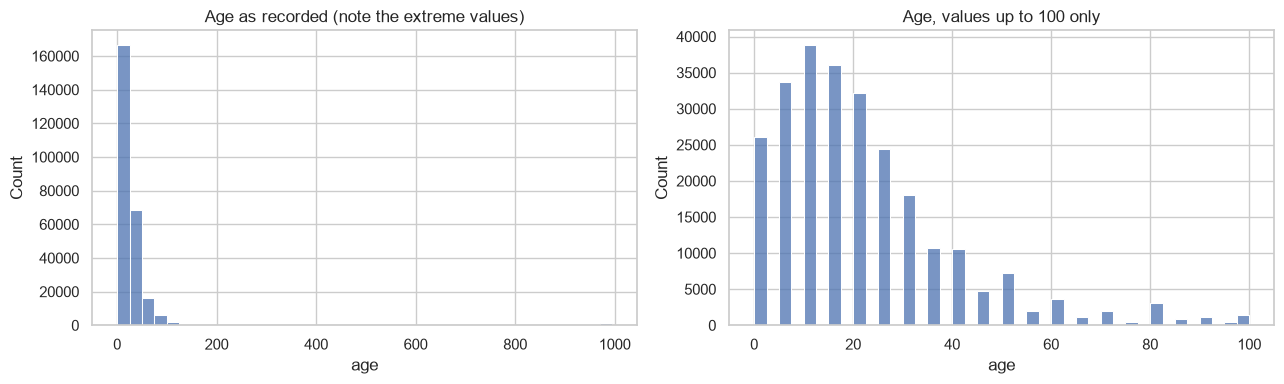

In [7]:
print(df_raw['age'].describe().round(2))
print()
print("Ages above 100 (most common):")
print(df_raw.loc[df_raw['age'] > 100, 'age'].value_counts().head(8))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df_raw['age'], bins=40, ax=axes[0]); axes[0].set_title('Age as recorded (note the extreme values)')
sns.histplot(df_raw.loc[df_raw['age'] <= 100, 'age'], bins=40, ax=axes[1]); axes[1].set_title('Age, values up to 100 only')
plt.tight_layout(); plt.show()

**Decision:** treat ages above 100 as unknown. Add a flag `age_unknown` (the fact that the age is unknown may itself be informative), and replace the value with the **training median**.

## 3.5 Outliers in the other numeric columns

,min,max,IQR lower,IQR upper,outliers,outliers %
column,,,,,,
count_floors_pre_eq,1,9,2.0,2.0,103978,39.90
area_percentage,1,100,-1.0,15.0,13557,5.20
height_percentage,2,32,1.0,9.0,7843,3.01
count_families,0,9,1.0,1.0,34486,13.23


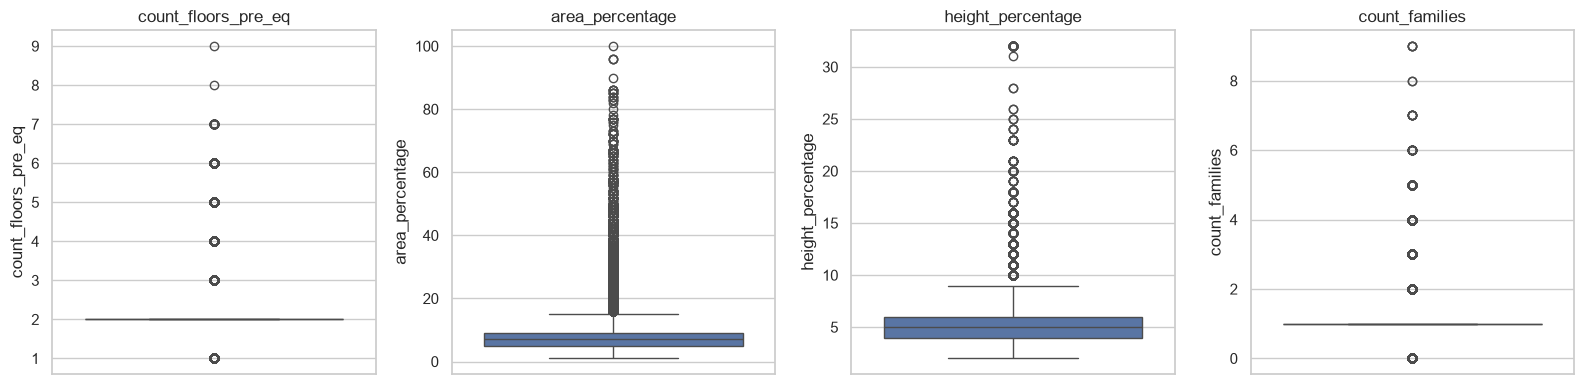

In [8]:
def iqr_report(data, cols):
    rows = []
    for c in cols:
        q1, q3 = data[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = int(((data[c] < lo) | (data[c] > hi)).sum())
        rows.append({'column': c, 'min': data[c].min(), 'max': data[c].max(),
                     'IQR lower': lo, 'IQR upper': hi,
                     'outliers': n_out, 'outliers %': round(100 * n_out / len(data), 2)})
    return pd.DataFrame(rows).set_index('column')

other_numeric = ['count_floors_pre_eq', 'area_percentage', 'height_percentage', 'count_families']
display(iqr_report(df_raw, other_numeric))

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, other_numeric):
    sns.boxplot(y=df_raw[c], ax=ax); ax.set_title(c)
plt.tight_layout(); plt.show()

The IQR rule flags many buildings for `count_floors_pre_eq` and `count_families` only because almost all values are identical (so the IQR is nearly zero). These are real buildings, not errors. **No rows are removed.** Tree models cope with large values, and extreme buildings may be informative for damage.

## 3.6 Logical consistency

In [9]:
secondary_cols = [c for c in df_raw.columns if c.startswith('has_secondary_use_')]
superstructure_cols = [c for c in df_raw.columns if c.startswith('has_superstructure_')]

secondary_sum = df_raw[secondary_cols].sum(axis=1)
print("has_secondary_use = 0 but a specific use is set:", int(((df_raw['has_secondary_use'] == 0) & (secondary_sum > 0)).sum()))
print("has_secondary_use = 1 but no specific use set   :", int(((df_raw['has_secondary_use'] == 1) & (secondary_sum == 0)).sum()))
print("Buildings with no superstructure material flag  :", int((df_raw[superstructure_cols].sum(axis=1) == 0).sum()))

has_secondary_use = 0 but a specific use is set: 0
has_secondary_use = 1 but no specific use set   : 0
Buildings with no superstructure material flag  : 0


## 3.7 One reusable cleaning function

Everything decided above is wrapped in `clean_data()`. It is applied to the training data now and to the test data in Section 10, with the **same** training median, so the two are treated identically.

In [10]:
def clean_data(data, age_median=None):
    """Flag and repair impossible ages. Returns the cleaned copy and the median that was used."""
    d = data.copy()
    d['age_unknown'] = ((d['age'] > 100) | d['age'].isna()).astype(int)
    d.loc[d['age_unknown'] == 1, 'age'] = np.nan
    if age_median is None:                      # training data: compute the median here
        age_median = d['age'].median()
    d['age'] = d['age'].fillna(age_median)
    return d, age_median


df, AGE_MEDIAN = clean_data(df_raw)

print("Median age used for unknown ages:", AGE_MEDIAN)
print("Buildings with unknown age:", int(df['age_unknown'].sum()), f"({df['age_unknown'].mean():.2%})")
print("Age range after cleaning:", df['age'].min(), "to", df['age'].max())

Median age used for unknown ages: 15.0
Buildings with unknown age: 2124 (0.82%)
Age range after cleaning: 0.0 to 100.0


# 4. Exploratory data analysis

Goal: understand which features relate to damage, so the feature engineering and the model choices are grounded in the data.

## 4.1 Target: damage grade

,buildings,percent
damage_grade,,
1,25124,9.64
2,148259,56.89
3,87218,33.47


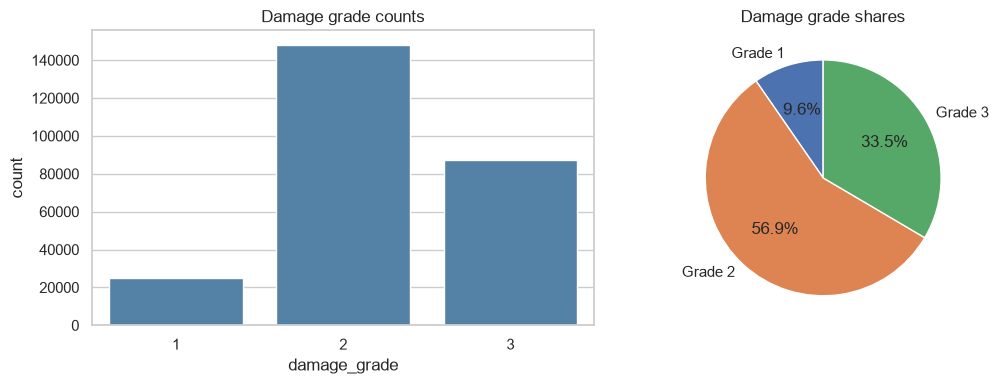

In [11]:
counts = df['damage_grade'].value_counts().sort_index()
pct = (counts / counts.sum() * 100).round(2)
display(pd.DataFrame({'buildings': counts, 'percent': pct}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x='damage_grade', ax=axes[0], color='steelblue')
axes[0].set_title('Damage grade counts')
axes[1].pie(counts, labels=['Grade 1', 'Grade 2', 'Grade 3'], autopct='%1.1f%%', startangle=90)
axes[1].set_title('Damage grade shares')
plt.tight_layout(); plt.show()

The classes are **imbalanced**: Grade 2 dominates and Grade 1 is rare (about 10%). Always compare models against the "predict Grade 2 for everything" baseline (about 57% micro-F1), and check Grade 1 performance separately.

## 4.2 Univariate: numeric features

,count,mean,std,min,25%,50%,75%,max
age,260601.0,20.96,18.49,0.0,10.0,15.0,30.0,100.0
area_percentage,260601.0,8.02,4.39,1.0,5.0,7.0,9.0,100.0
height_percentage,260601.0,5.43,1.92,2.0,4.0,5.0,6.0,32.0
count_floors_pre_eq,260601.0,2.13,0.73,1.0,2.0,2.0,2.0,9.0
count_families,260601.0,0.98,0.42,0.0,1.0,1.0,1.0,9.0


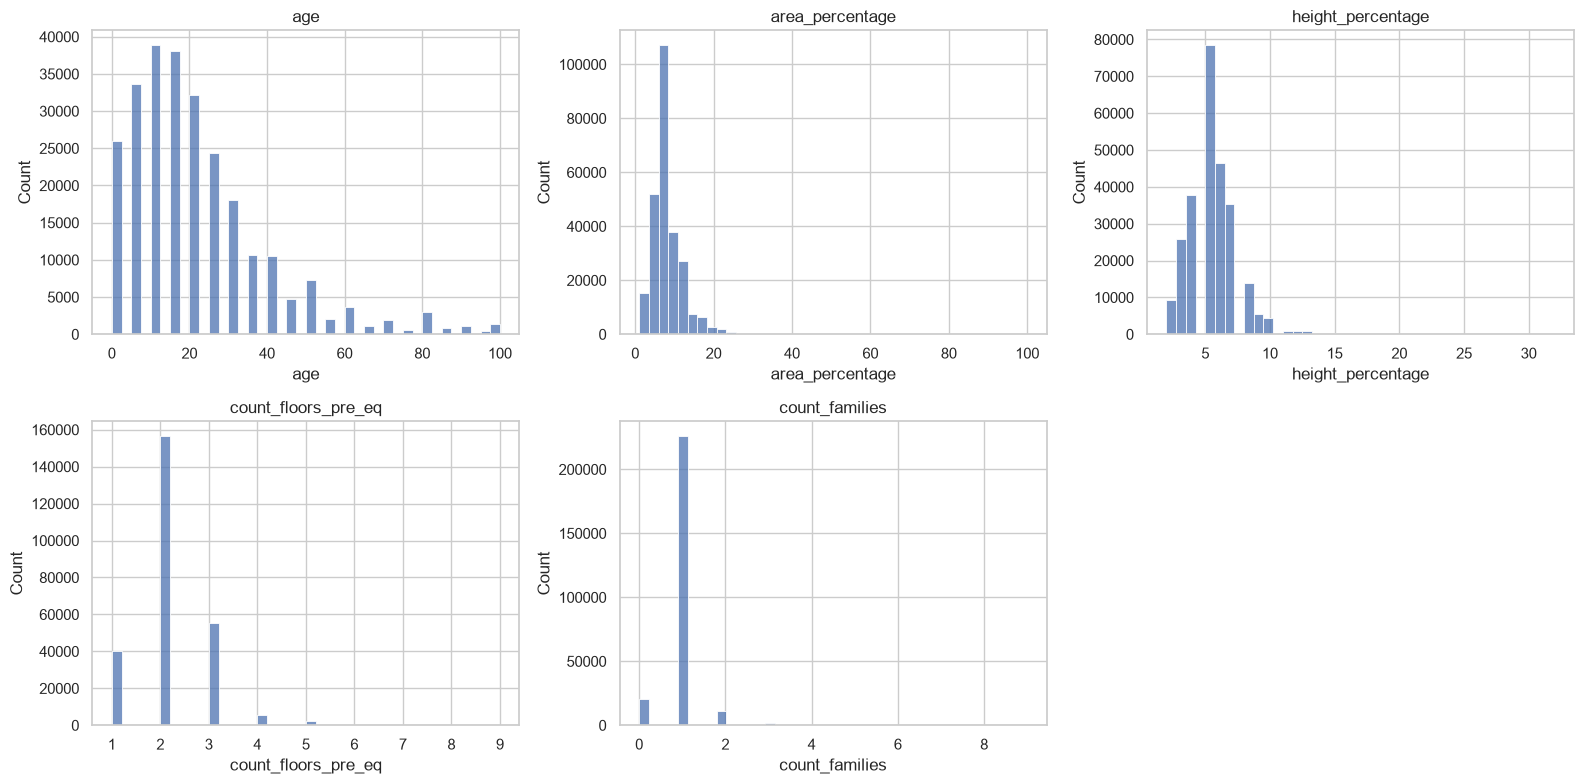

In [12]:
numeric_cols = ['age', 'area_percentage', 'height_percentage', 'count_floors_pre_eq', 'count_families']
display(df[numeric_cols].describe().T.round(2))

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.flatten(), numeric_cols):
    sns.histplot(df[c], bins=40, ax=ax); ax.set_title(c)
axes.flatten()[-1].axis('off')
plt.tight_layout(); plt.show()

## 4.3 Univariate: categorical features

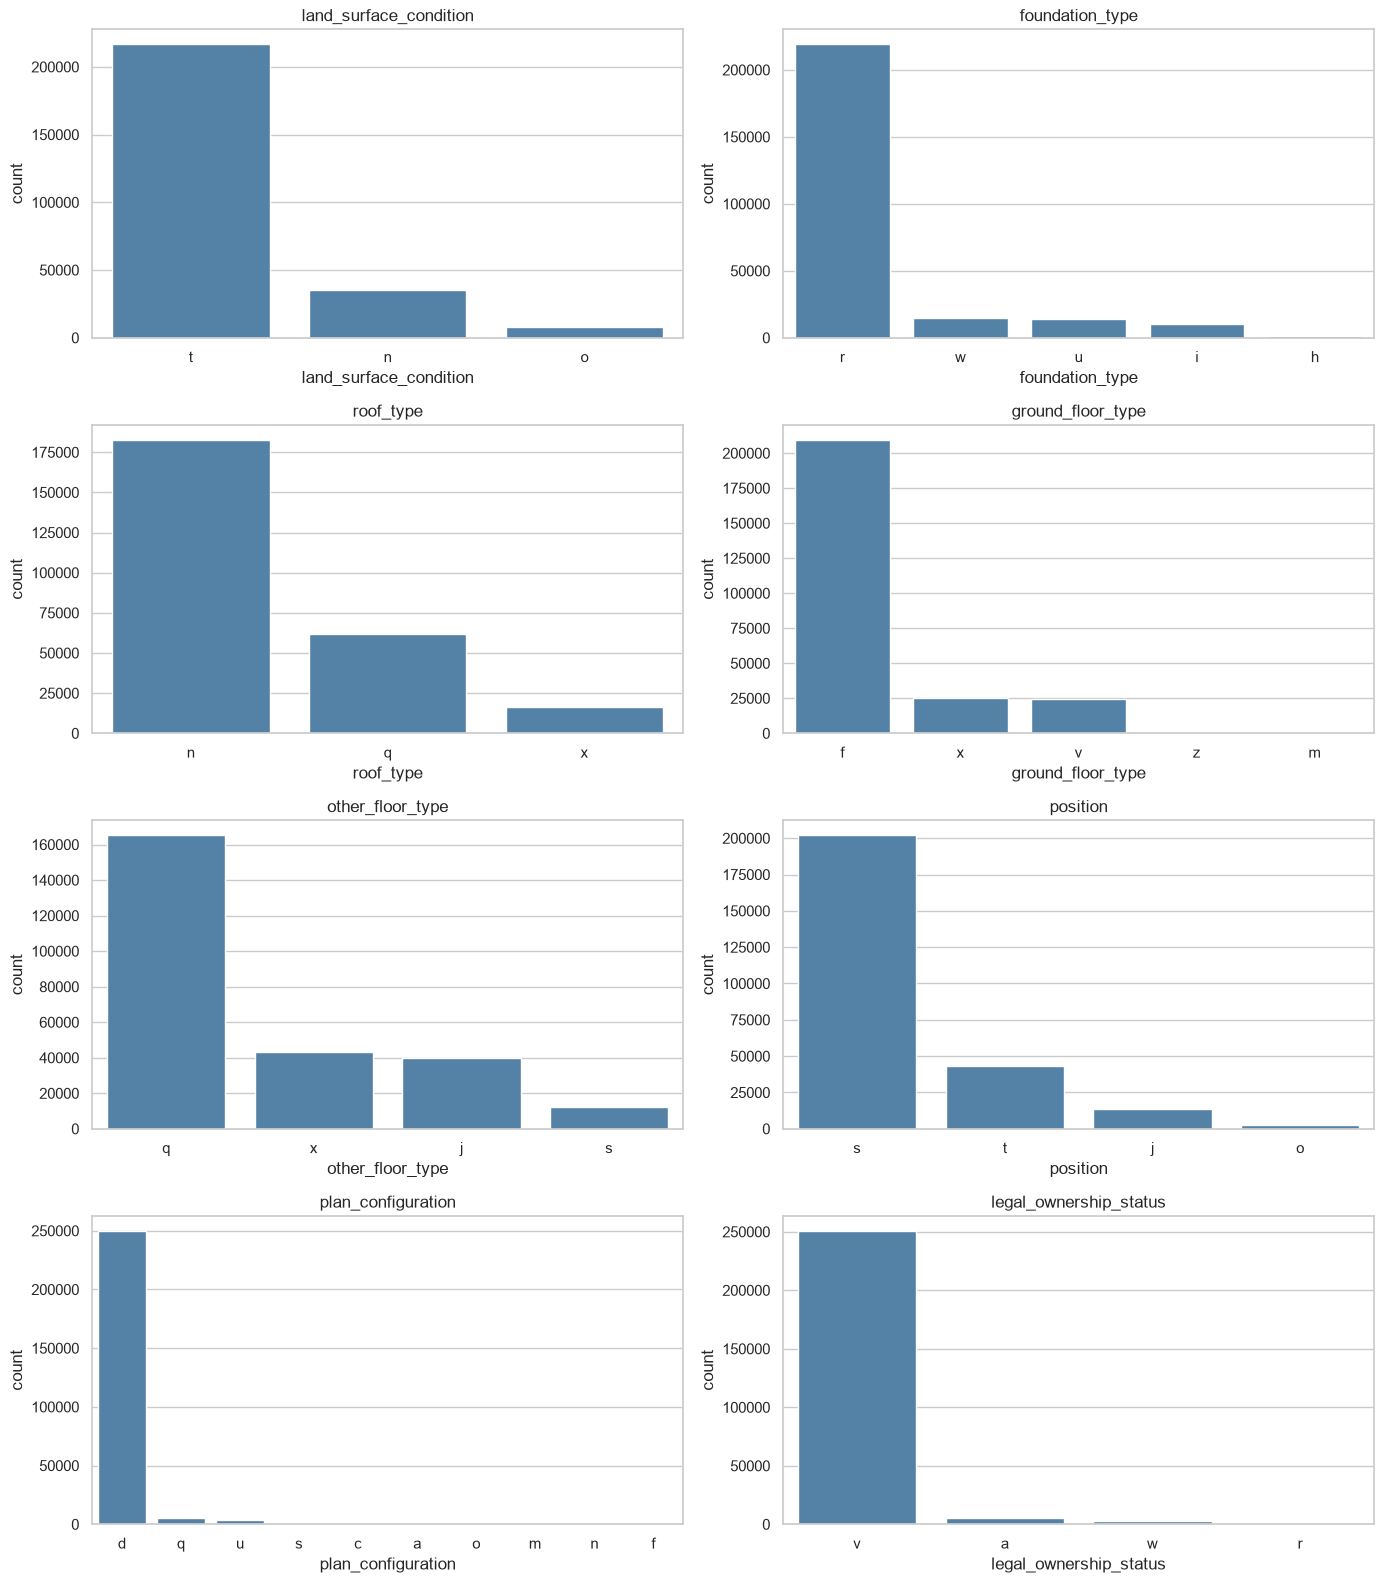

In [13]:
categorical_cols = ['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type',
                    'other_floor_type', 'position', 'plan_configuration', 'legal_ownership_status']

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
for ax, c in zip(axes.flatten(), categorical_cols):
    sns.countplot(data=df, x=c, order=df[c].value_counts().index, ax=ax, color='steelblue')
    ax.set_title(c)
plt.tight_layout(); plt.show()

Categories are anonymised letters, so the values cannot be interpreted directly. What matters is **which categories are linked to more damage** (Section 4.5).

## 4.4 Univariate: binary flags

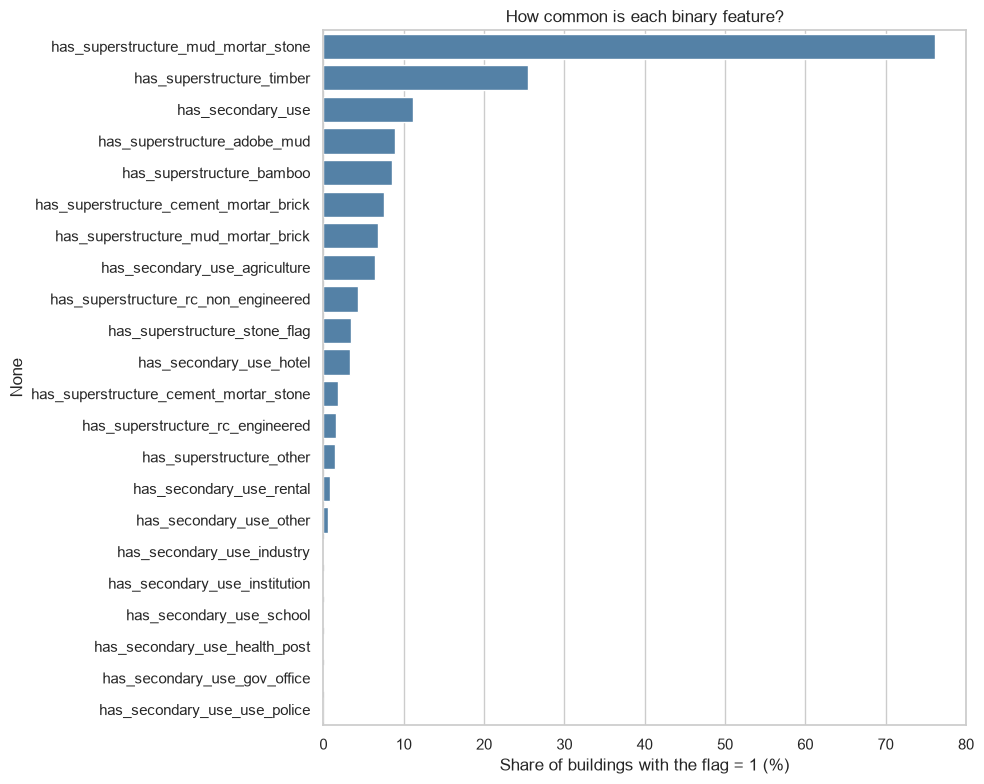

In [14]:
binary_cols_eda = [c for c in df.columns if c.startswith('has_')]
share_one = (df[binary_cols_eda].mean() * 100).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x=share_one.values, y=share_one.index, color='steelblue')
plt.xlabel('Share of buildings with the flag = 1 (%)'); plt.title('How common is each binary feature?')
plt.tight_layout(); plt.show()

Most `has_secondary_use_*` flags are almost always 0, so individually they carry little information. The summary feature `secondary_use_count` (Section 5) is more useful.

## 4.5 Bivariate: features versus damage grade

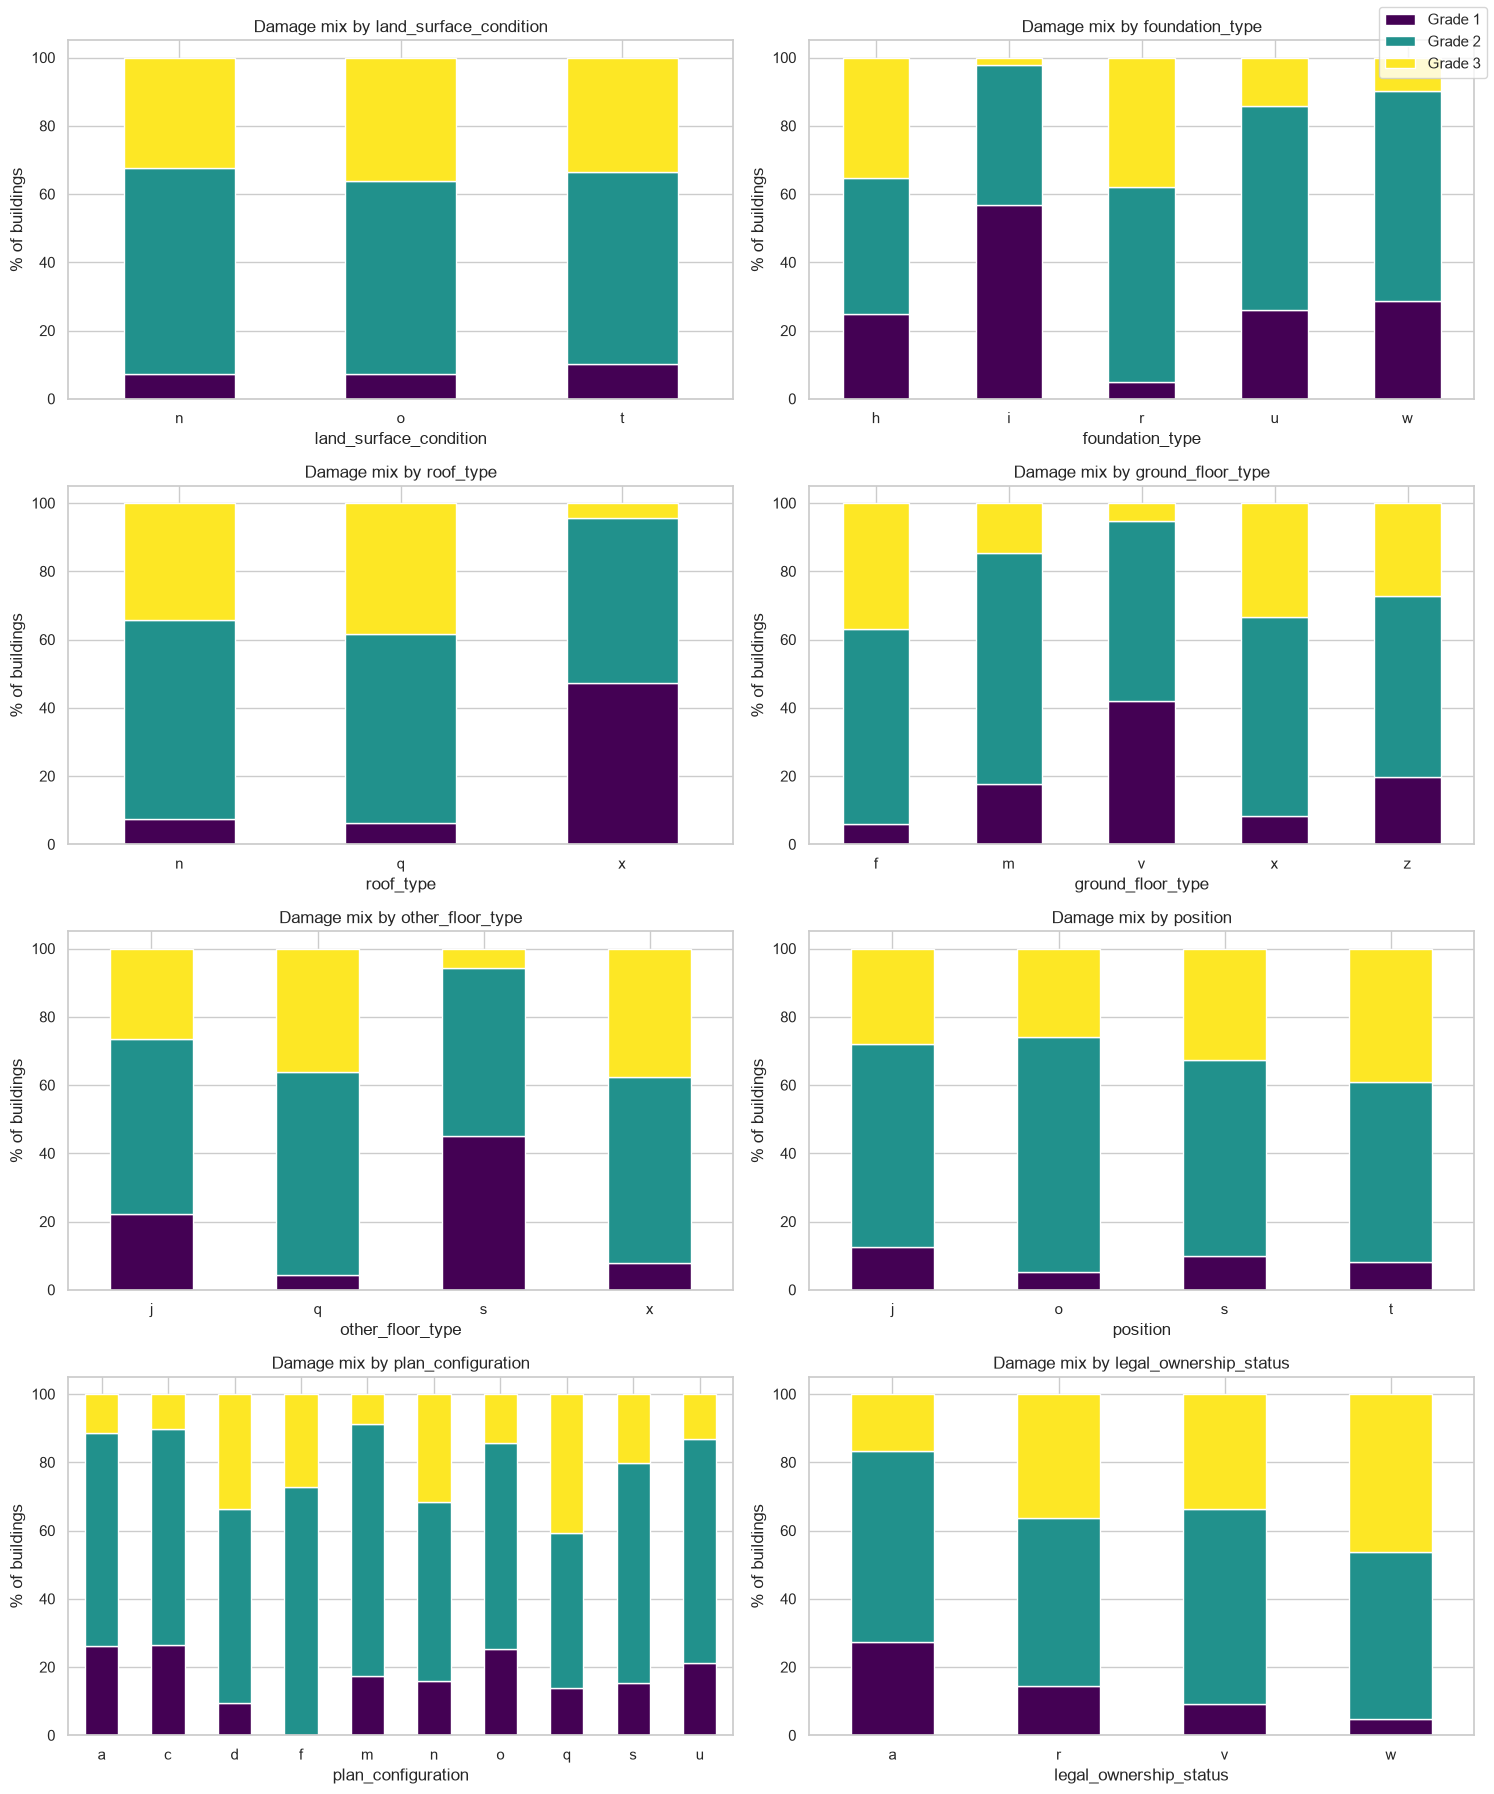

In [15]:
fig, axes = plt.subplots(4, 2, figsize=(15, 18))
for ax, c in zip(axes.flatten(), categorical_cols):
    props = pd.crosstab(df[c], df['damage_grade'], normalize='index') * 100
    props.plot(kind='bar', stacked=True, ax=ax, colormap='viridis', legend=False)
    ax.set_title(f'Damage mix by {c}'); ax.set_ylabel('% of buildings'); ax.tick_params(axis='x', rotation=0)
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, [f'Grade {l}' for l in labels], loc='upper right')
plt.tight_layout(); plt.show()

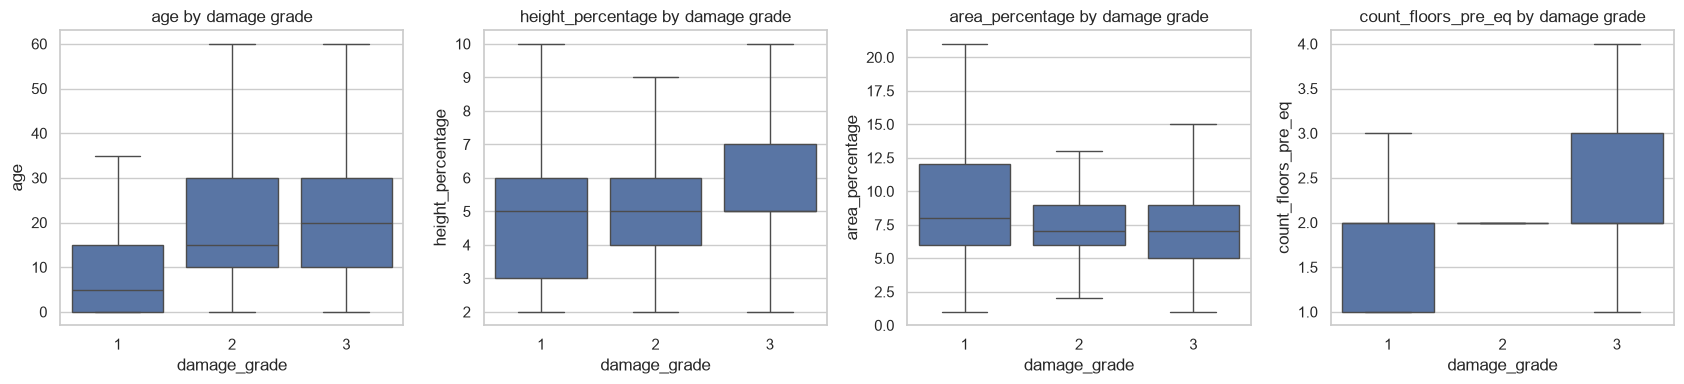

In [16]:
known_age = df[df['age_unknown'] == 0]
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, c in zip(axes, ['age', 'height_percentage', 'area_percentage', 'count_floors_pre_eq']):
    sns.boxplot(data=known_age, x='damage_grade', y=c, ax=ax, showfliers=False)
    ax.set_title(f'{c} by damage grade')
plt.tight_layout(); plt.show()

### Construction material versus damage

,material,buildings with material,Grade 3 % (material present),Grade 3 % (material absent),difference
0,mud_mortar_stone,198561,38.2,18.3,19.9
1,stone_flag,8947,47.3,33.0,14.3
2,adobe_mud,23101,37.2,33.1,4.1
3,mud_mortar_brick,17761,30.6,33.7,-3.1
4,timber,66450,28.0,35.3,-7.3
5,other,3905,25.6,33.6,-8.0
6,bamboo,22154,24.0,34.3,-10.3
7,cement_mortar_stone,4752,14.2,33.8,-19.6
8,rc_non_engineered,11099,12.7,34.4,-21.7
9,cement_mortar_brick,19615,5.6,35.7,-30.1


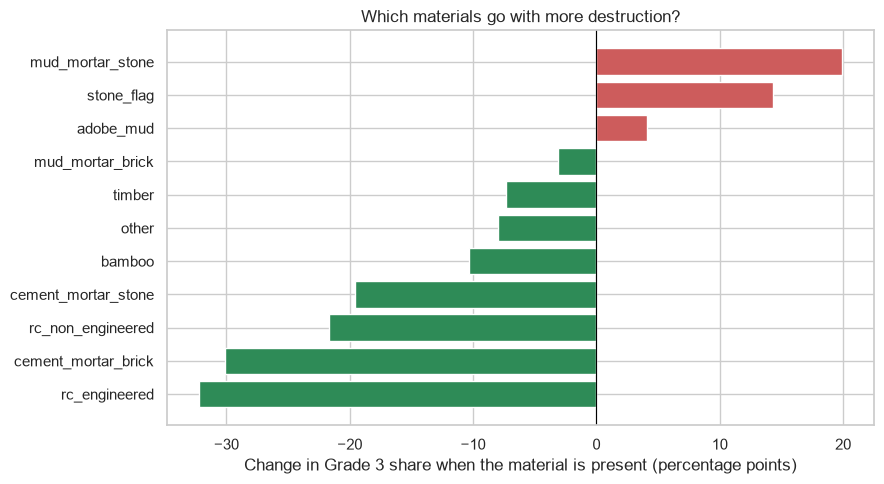

In [17]:
rows = []
for c in superstructure_cols:
    g3 = (df['damage_grade'] == 3)
    rows.append({'material': c.replace('has_superstructure_', ''),
                 'buildings with material': int(df[c].sum()),
                 'Grade 3 % (material present)': round(g3[df[c] == 1].mean() * 100, 1),
                 'Grade 3 % (material absent)':  round(g3[df[c] == 0].mean() * 100, 1)})
material_df = pd.DataFrame(rows)
material_df['difference'] = material_df['Grade 3 % (material present)'] - material_df['Grade 3 % (material absent)']
material_df = material_df.sort_values('difference', ascending=False).reset_index(drop=True)
display(material_df)

plt.figure(figsize=(9, 5))
colors = ['indianred' if v > 0 else 'seagreen' for v in material_df['difference']]
plt.barh(material_df['material'][::-1], material_df['difference'][::-1], color=colors[::-1])
plt.axvline(0, color='black', lw=0.8)
plt.xlabel('Change in Grade 3 share when the material is present (percentage points)')
plt.title('Which materials go with more destruction?')
plt.tight_layout(); plt.show()

**What this shows.** The material a building is made of matters a lot. Buildings with mud mortar and stone walls are by far the most common type (198,561 of the 260,601) and ended up in Grade 3 38.2% of the time, compared with 18.3% for buildings without that material. At the other end, engineered reinforced concrete buildings reached Grade 3 only 1.8% of the time and cement mortar brick buildings 5.6%. Mud and stone is the dangerous side, cement and concrete the safe one.

### Geography versus damage

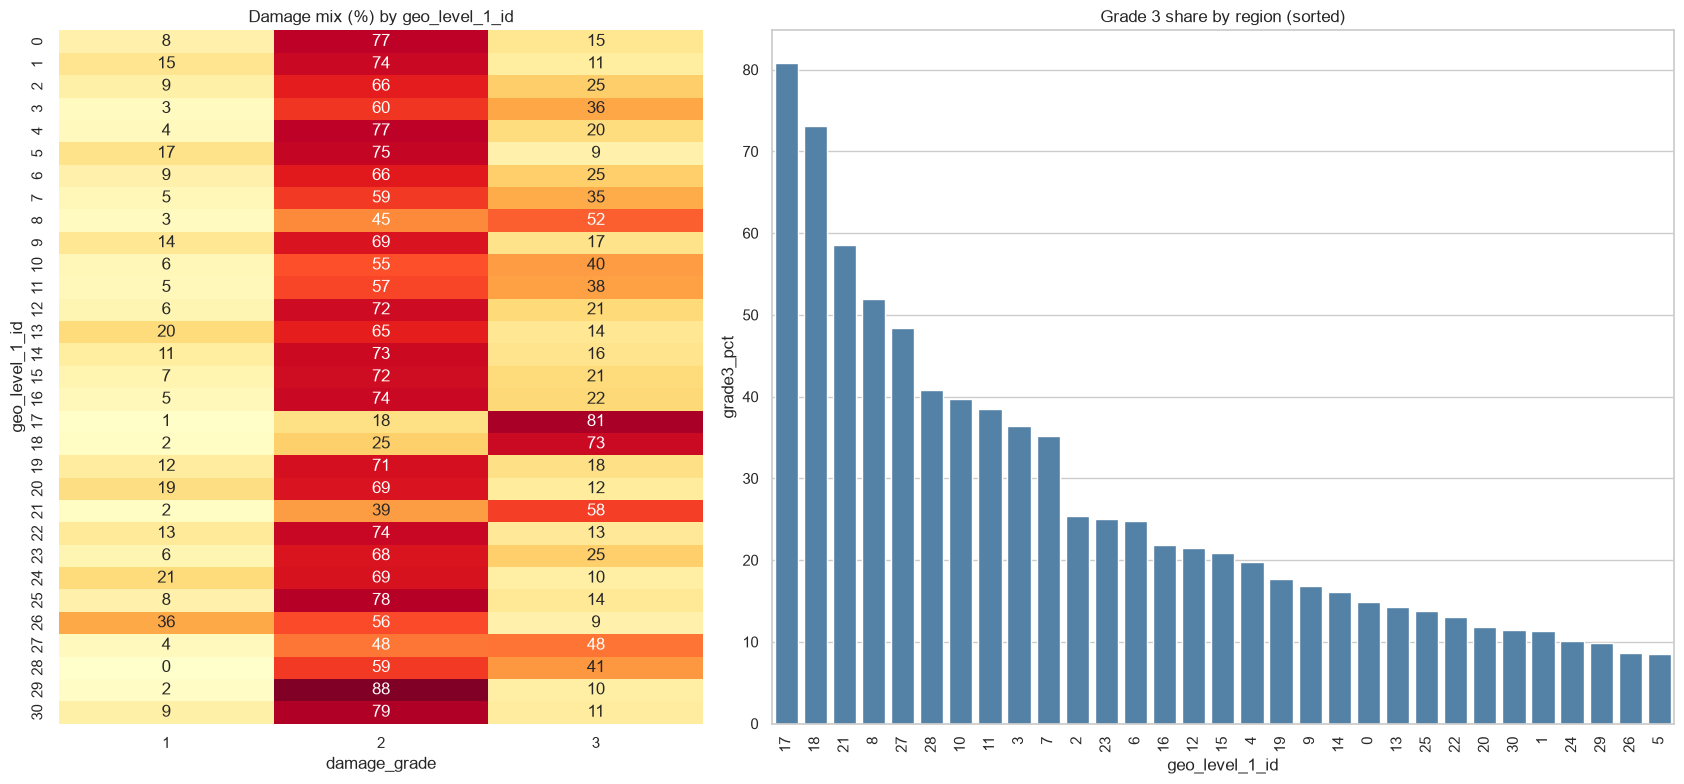

In [18]:
geo1 = (df.groupby('geo_level_1_id')['damage_grade']
          .agg(buildings='count', grade3_pct=lambda s: (s == 3).mean() * 100)
          .sort_values('grade3_pct', ascending=False))

geo_mix = pd.crosstab(df['geo_level_1_id'], df['damage_grade'], normalize='index') * 100
fig, axes = plt.subplots(1, 2, figsize=(17, 8), gridspec_kw={'width_ratios': [1, 1.4]})
sns.heatmap(geo_mix.round(1), annot=True, fmt='.0f', cmap='YlOrRd', ax=axes[0], cbar=False)
axes[0].set_title('Damage mix (%) by geo_level_1_id')
sns.barplot(data=geo1.reset_index(), x='geo_level_1_id', y='grade3_pct', color='steelblue',
            order=geo1.index, ax=axes[1])
axes[1].set_title('Grade 3 share by region (sorted)'); axes[1].tick_params(axis='x', rotation=90)
plt.tight_layout(); plt.show()

Regions differ **a lot**. The share of Grade 3 buildings runs from 8.6% in region 5 up to 80.8% in region 17, with regions 18 and 21 also far above average. That is why I expect location features to carry the most weight, and why Section 5 spends so much effort on encoding the region IDs properly.

## 4.6 Multivariate analysis

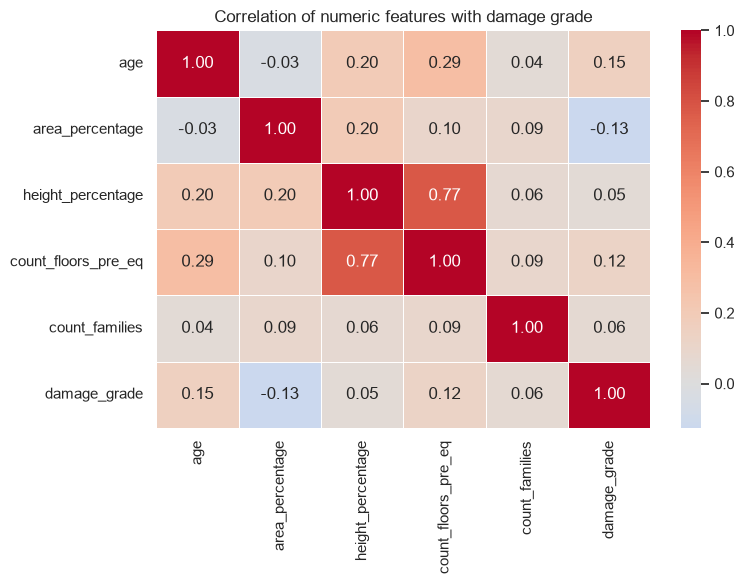

In [19]:
corr = df[numeric_cols + ['damage_grade']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation of numeric features with damage grade')
plt.tight_layout(); plt.show()

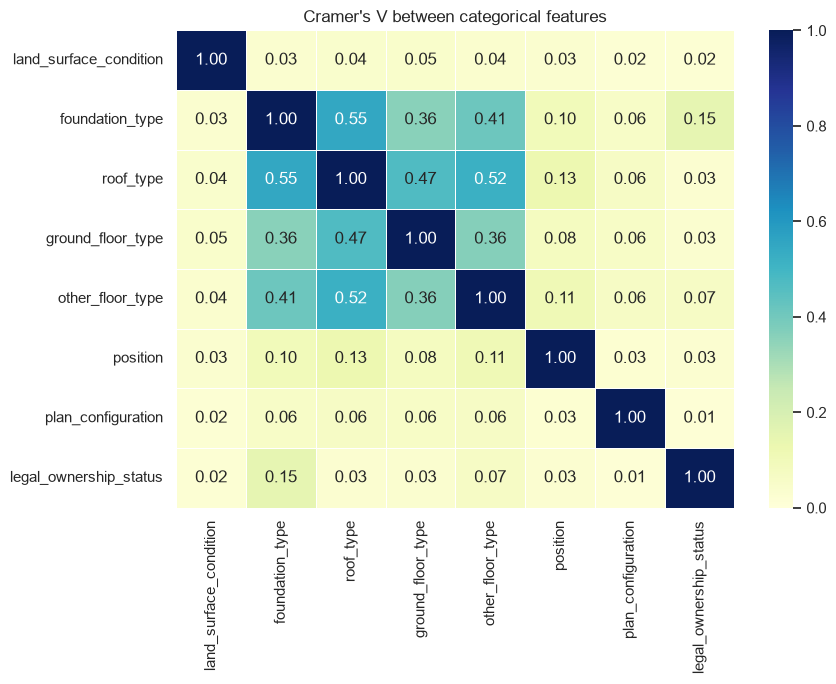

In [20]:
def cramers_v(x, y):
    """Bias-corrected Cramer's V between two categorical series (0 = unrelated, 1 = identical)."""
    cm = pd.crosstab(x, y)
    r, k = cm.shape
    if r < 2 or k < 2:
        return 0.0
    n = cm.to_numpy().sum()
    chi2 = chi2_contingency(cm, correction=False)[0]
    phi2 = max(0, chi2 / n - ((k - 1) * (r - 1)) / (n - 1))
    r_c = r - ((r - 1) ** 2) / (n - 1)
    k_c = k - ((k - 1) ** 2) / (n - 1)
    return float(np.sqrt(phi2 / max(1e-12, min(k_c - 1, r_c - 1))))

cramers = pd.DataFrame(index=categorical_cols, columns=categorical_cols, dtype=float)
for a in categorical_cols:
    for b in categorical_cols:
        cramers.loc[a, b] = 1.0 if a == b else cramers_v(df[a], df[b])

plt.figure(figsize=(9, 7))
sns.heatmap(cramers, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1, linewidths=0.5)
plt.title("Cramer's V between categorical features")
plt.tight_layout(); plt.show()

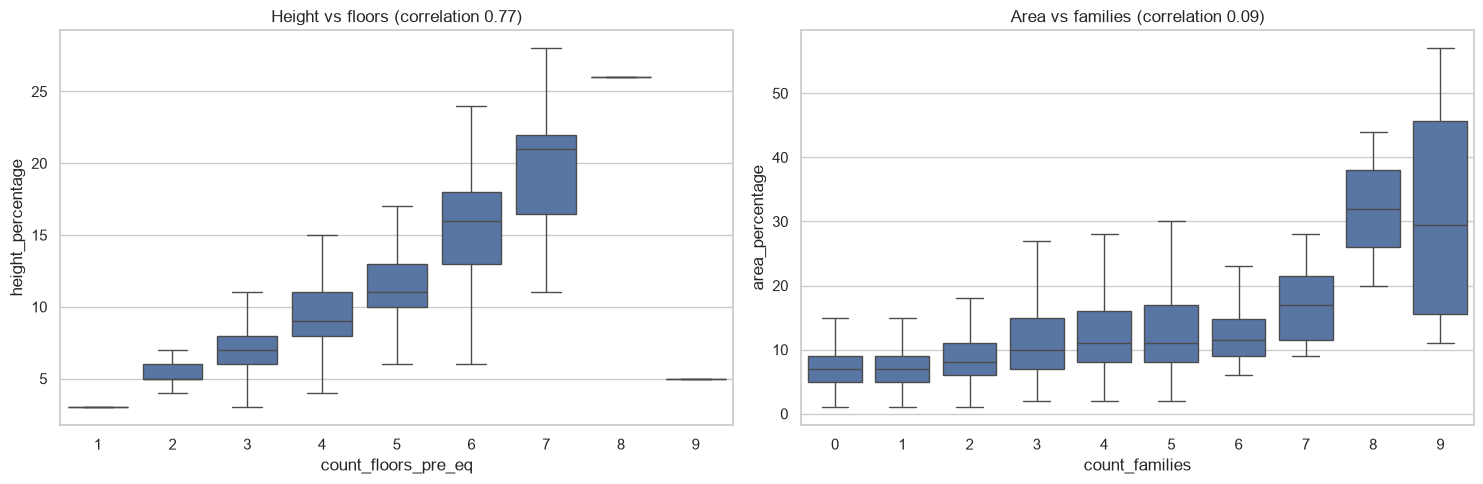

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df, x='count_floors_pre_eq', y='height_percentage', ax=axes[0], showfliers=False)
axes[0].set_title(f"Height vs floors (correlation {df['count_floors_pre_eq'].corr(df['height_percentage']):.2f})")
sns.boxplot(data=df, x='count_families', y='area_percentage', ax=axes[1], showfliers=False)
axes[1].set_title(f"Area vs families (correlation {df['area_percentage'].corr(df['count_families']):.2f})")
plt.tight_layout(); plt.show()

In [22]:
# Which combinations of material and foundation carry the most Grade 3 damage?
for material in ['has_superstructure_mud_mortar_stone', 'has_superstructure_rc_engineered']:
    table = (df.groupby([material, 'foundation_type'])['damage_grade']
               .agg(buildings='count', grade3_pct=lambda s: round((s == 3).mean() * 100, 1))
               .reset_index().query('buildings >= 200')
               .sort_values('grade3_pct', ascending=False))
    print(f"\n{material} x foundation_type (groups with at least 200 buildings)")
    display(table.head(6))


has_superstructure_mud_mortar_stone x foundation_type (groups with at least 200 buildings)


,has_superstructure_mud_mortar_stone,foundation_type,buildings,grade3_pct
7,1,r,188880,39.1
0,0,h,1230,36.6
8,1,u,4281,31.0
2,0,r,30316,30.2
5,1,h,218,28.0
9,1,w,4992,12.5



has_superstructure_rc_engineered x foundation_type (groups with at least 200 buildings)


,has_superstructure_rc_engineered,foundation_type,buildings,grade3_pct
2,0,r,219088,37.9
0,0,h,1444,35.4
3,0,u,13888,14.5
4,0,w,15112,9.9
8,1,u,372,4.8
1,0,i,6936,2.5


## 4.7 Key takeaways (computed from the data)

In [23]:
g3 = (df['damage_grade'] == 3)
is_mud = (df[['has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone',
              'has_superstructure_mud_mortar_brick']].sum(axis=1) > 0)
is_rc_eda = (df[['has_superstructure_rc_engineered', 'has_superstructure_rc_non_engineered']].sum(axis=1) > 0)

print("1. Class balance: Grade 1 / 2 / 3 = " + " / ".join(f"{v:.1f}%" for v in pct.values))
print(f"2. Mud-based buildings: {g3[is_mud].mean():.1%} Grade 3   |   reinforced concrete: {g3[is_rc_eda].mean():.1%} Grade 3")
print(f"3. Regions differ widely: Grade 3 share ranges from {geo1['grade3_pct'].min():.1f}% "
      f"(region {geo1['grade3_pct'].idxmin()}) to {geo1['grade3_pct'].max():.1f}% (region {geo1['grade3_pct'].idxmax()})")
print(f"4. Grade 3 share by floors: " +
      ", ".join(f"{int(k)} floor(s): {v:.0%}" for k, v in g3.groupby(df['count_floors_pre_eq'].clip(upper=4)).mean().items()))
print(f"5. {df['age_unknown'].mean():.2%} of buildings have an unknown age (flagged, not dropped)")

1. Class balance: Grade 1 / 2 / 3 = 9.6% / 56.9% / 33.5%
2. Mud-based buildings: 37.7% Grade 3   |   reinforced concrete: 9.8% Grade 3
3. Regions differ widely: Grade 3 share ranges from 8.6% (region 5) to 80.8% (region 17)
4. Grade 3 share by floors: 1 floor(s): 26%, 2 floor(s): 32%, 3 floor(s): 44%, 4 floor(s): 24%
5. 0.82% of buildings have an unknown age (flagged, not dropped)


# 5. Feature engineering and preprocessing

## 5.1 Column groups

In [24]:
geo_cols = ['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id']

cat_cols = ['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type',
            'other_floor_type', 'position', 'plan_configuration', 'legal_ownership_status']

## 5.2 Row-level features

These use only the building's own values, so they are safe to create before splitting the data. They turn the EDA findings into model inputs: grouped materials, size and shape ratios, age buckets, and risk interactions (old or tall mud buildings).

In [25]:
def add_features(data):
    d = data.copy()

    for c in geo_cols:                                   # plain integers; encoders treat them as labels
        d[c] = d[c].astype(int)

    sup_cols = [c for c in d.columns if c.startswith('has_superstructure_')]
    sec_cols = [c for c in d.columns if c.startswith('has_secondary_use_')]

    d['superstructure_count'] = d[sup_cols].sum(axis=1)
    d['secondary_use_count']  = d[sec_cols].sum(axis=1)

    d['is_rc'] = ((d['has_superstructure_rc_engineered'] == 1) |
                  (d['has_superstructure_rc_non_engineered'] == 1)).astype(int)
    d['is_mud_based'] = ((d['has_superstructure_adobe_mud'] == 1) |
                         (d['has_superstructure_mud_mortar_stone'] == 1) |
                         (d['has_superstructure_mud_mortar_brick'] == 1)).astype(int)
    d['is_cement_based'] = ((d['has_superstructure_cement_mortar_stone'] == 1) |
                            (d['has_superstructure_cement_mortar_brick'] == 1)).astype(int)

    d['height_per_floor'] = d['height_percentage'] / d['count_floors_pre_eq'].clip(lower=1)
    d['area_x_height']    = d['area_percentage'] * d['height_percentage']

    d['log_age'] = np.log1p(d['age'])
    d['age_bucket'] = pd.cut(d['age'], bins=[-1, 5, 10, 20, 30, 50, np.inf], labels=False).astype(int)

    d['old_mud_building']  = ((d['age'] >= 30) & (d['is_mud_based'] == 1)).astype(int)
    d['tall_mud_building'] = ((d['count_floors_pre_eq'] >= 3) & (d['is_mud_based'] == 1)).astype(int)
    return d


X = add_features(df.drop(columns=['building_id', 'damage_grade']))
y = df['damage_grade'].astype(int) - 1          # 1,2,3 -> 0,1,2 (required by XGBoost and LightGBM)

engineered_bin = ['is_rc', 'is_mud_based', 'is_cement_based', 'old_mud_building', 'tall_mud_building']
bin_cols = [c for c in X.columns if c.startswith('has_')] + ['age_unknown'] + engineered_bin
num_cols = ['age', 'log_age', 'age_bucket', 'area_percentage', 'height_percentage',
            'count_floors_pre_eq', 'count_families', 'superstructure_count', 'secondary_use_count',
            'height_per_floor', 'area_x_height']

used = set(geo_cols + cat_cols + bin_cols + num_cols)
assert used == set(X.columns), (set(X.columns) - used, used - set(X.columns))
print("Feature table:", X.shape)

Feature table: (260601, 50)


## 5.3 Train / validation split

Stratified, so both parts keep the 10% / 57% / 33% class mix. `X_valid` is used only for comparing finished models, never for fitting or tuning.

In [26]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Valid:", X_valid.shape)
print("Train class shares:", y_train.value_counts(normalize=True).sort_index().round(3).to_dict())
print("Valid class shares:", y_valid.value_counts(normalize=True).sort_index().round(3).to_dict())

Train: (208480, 50) | Valid: (52121, 50)
Train class shares: {0: 0.096, 1: 0.569, 2: 0.335}
Valid class shares: {0: 0.096, 1: 0.569, 2: 0.335}


## 5.4 Target encoding for the geo columns

`geo_level_2_id` (about 1,400 regions) and `geo_level_3_id` (about 11,600 regions) are too large for one-hot encoding. This encoder replaces each region with the smoothed share of Grade 1, 2 and 3 buildings found there.

To avoid **target leakage**, training rows are encoded **out-of-fold**: a row is encoded with statistics from the other folds, never from its own label. Because the encoder lives inside the sklearn pipeline, cross-validation stays leak-free.

In [27]:
class GeoTargetEncoder(BaseEstimator, TransformerMixin):
    """Smoothed, out-of-fold class-rate encoding for high-cardinality columns."""

    def __init__(self, cols, n_splits=5, smoothing=20, random_state=42):
        self.cols = cols
        self.n_splits = n_splits
        self.smoothing = smoothing
        self.random_state = random_state

    def _fit_maps(self, X, y):
        Y = np.column_stack([(y == k).astype(float) for k in self.classes_])
        prior = Y.mean(axis=0)
        maps = {}
        for col in self.cols:
            grp = pd.DataFrame(Y).groupby(X[col].to_numpy())
            sums, counts = grp.sum(), grp.size()
            enc = (sums.values + prior * self.smoothing) / (counts.values[:, None] + self.smoothing)
            maps[col] = pd.DataFrame(enc, index=sums.index)
        return maps, prior

    def _apply(self, X, maps, prior):
        parts = []
        for col in self.cols:
            enc = maps[col].reindex(X[col].to_numpy()).to_numpy()
            parts.append(np.where(np.isnan(enc), prior, enc))     # unseen region -> overall rate
        return np.hstack(parts)

    def fit(self, X, y):
        X = pd.DataFrame(X).reset_index(drop=True)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        self.maps_, self.prior_ = self._fit_maps(X, y)
        return self

    def fit_transform(self, X, y):
        X = pd.DataFrame(X).reset_index(drop=True)
        y = np.asarray(y)
        self.fit(X, y)
        out = np.zeros((len(X), len(self.cols) * len(self.classes_)))
        skf = StratifiedKFold(self.n_splits, shuffle=True, random_state=self.random_state)
        for tr, va in skf.split(X, y):
            maps, prior = self._fit_maps(X.iloc[tr], y[tr])
            out[va] = self._apply(X.iloc[va], maps, prior)
        return out

    def transform(self, X):
        X = pd.DataFrame(X).reset_index(drop=True)
        return self._apply(X, self.maps_, self.prior_)

## 5.5 Neighbourhood features (`GeoAggregator`)

Target encoding says how damaged a region was. These features describe **what the region looks like** and **how each building differs from its neighbours**: number of buildings, average age, height, area, floors, share of mud and reinforced-concrete buildings, and the building's own difference from those averages. A tall building in a region of low buildings is treated differently from a tall building in a region of tall buildings.

They use **no labels**, so there is no target leakage. They are computed inside the pipeline, from the training rows only.

In [28]:
class GeoAggregator(BaseEstimator, TransformerMixin):
    """Adds label-free neighbourhood statistics for geo levels 2 and 3."""

    LEVELS    = ('geo_level_2_id', 'geo_level_3_id')
    AGG_COLS  = ['age', 'height_percentage', 'area_percentage', 'count_floors_pre_eq',
                 'is_mud_based', 'is_rc', 'superstructure_count']
    DIFF_COLS = ['age', 'height_percentage', 'area_percentage', 'count_floors_pre_eq']

    @staticmethod
    def _tag(level):
        return 'g' + level.split('_')[2]                     # geo_level_3_id -> g3

    @classmethod
    def output_columns(cls):
        names = []
        for lvl in cls.LEVELS:
            tag = cls._tag(lvl)
            names += [f"{tag}_mean_{c}" for c in cls.AGG_COLS]
            names += [f"{tag}_count"]
            names += [f"{c}_vs_{tag}" for c in cls.DIFF_COLS]
        return names

    def fit(self, X, y=None):
        self.stats_ = {}
        for lvl in self.LEVELS:
            tag = self._tag(lvl)
            grp = X.groupby(lvl)
            stats = grp[self.AGG_COLS].mean().add_prefix(f"{tag}_mean_")
            stats[f"{tag}_count"] = grp.size()
            self.stats_[lvl] = stats
        return self

    def transform(self, X):
        out = X.copy()
        for lvl, stats in self.stats_.items():
            tag = self._tag(lvl)
            joined = stats.reindex(X[lvl].to_numpy())
            joined[f"{tag}_count"] = joined[f"{tag}_count"].fillna(0)   # unseen region -> 0 buildings
            for c in joined.columns:
                out[c] = joined[c].to_numpy()
            for c in self.DIFF_COLS:
                out[f"{c}_vs_{tag}"] = X[c].to_numpy() - joined[f"{tag}_mean_{c}"].to_numpy()
        return out


GEO_AGG_COLS = GeoAggregator.output_columns()
print(len(GEO_AGG_COLS), "neighbourhood features, for example:", GEO_AGG_COLS[:5])

24 neighbourhood features, for example: ['g2_mean_age', 'g2_mean_height_percentage', 'g2_mean_area_percentage', 'g2_mean_count_floors_pre_eq', 'g2_mean_is_mud_based']


## 5.6 Preprocessing pipeline

Every model is one pipeline: **neighbourhood features, then preprocessing, then the model**.

- Categorical columns and `geo_level_1_id`: one-hot encoded
- `geo_level_2_id` and `geo_level_3_id`: target encoded (and also kept as raw numbers for tree models)
- Numeric columns: scaled and imputed for linear models only; LightGBM, XGBoost and CatBoost accept missing values directly
- Binary flags: passed through

In [29]:
def build_preprocessor(scale=False, impute=False):
    num_steps = []
    if impute: num_steps.append(('impute', SimpleImputer(strategy='median')))
    if scale:  num_steps.append(('scale', StandardScaler()))
    num_transformer = Pipeline(num_steps) if num_steps else 'passthrough'

    transformers = [
        ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols + ['geo_level_1_id']),
        ('num', num_transformer, num_cols + GEO_AGG_COLS),
        ('bin', 'passthrough', bin_cols),
        ('geo_te', GeoTargetEncoder(cols=geo_cols), geo_cols),
    ]
    if not scale:
        transformers.append(('geo_raw', 'passthrough', geo_cols))
    return ColumnTransformer(transformers, remainder='drop')


def make_pipeline(model, scale=False, impute=False):
    return Pipeline([
        ('geoagg', GeoAggregator()),
        ('prep', build_preprocessor(scale=scale, impute=impute)),
        ('model', model),
    ])


# Quick check: how many validation buildings sit in a geo_level_3 region the training data has not seen?
_geo = GeoAggregator().fit(X_train).transform(X_valid)
print("Validation rows whose geo_level_3 region is absent from the training data:",
      f"{_geo['g3_count'].eq(0).mean():.1%} (these get missing neighbourhood values, handled by the models)")

Validation rows whose geo_level_3 region is absent from the training data: 0.5% (these get missing neighbourhood values, handled by the models)


# 6. Baseline models and comparison

Models go from simple to strong. **Micro-F1** is the competition metric. For single-label multiclass problems it equals accuracy, so macro-F1 and per-class F1 are reported too, to show how well the rare Grade 1 class is handled.

In [30]:
def score_row(name, pred, kind='single'):
    pc = f1_score(y_valid, pred, average=None)
    return {'Model': name, 'Micro F1': f1_score(y_valid, pred, average='micro'),
            'Macro F1': f1_score(y_valid, pred, average='macro'),
            'F1 Grade 1': pc[0], 'F1 Grade 2': pc[1], 'F1 Grade 3': pc[2]}


def make_xgb(n_estimators=None):
    return XGBClassifier(n_estimators=n_estimators or XGB_TREES, learning_rate=0.05, max_depth=8,
                         subsample=0.8, colsample_bytree=0.6, min_child_weight=3,
                         tree_method='hist', eval_metric='mlogloss', n_jobs=-1, random_state=RANDOM_STATE)


baseline_models = {
    'Baseline (most frequent)': make_pipeline(DummyClassifier(strategy='most_frequent')),
    'Logistic Regression': make_pipeline(LogisticRegression(max_iter=500), scale=True, impute=True),
    'Decision Tree': make_pipeline(DecisionTreeClassifier(max_depth=12, min_samples_leaf=20,
                                                          random_state=RANDOM_STATE), impute=True),
    'Random Forest': make_pipeline(RandomForestClassifier(n_estimators=RF_TREES, min_samples_leaf=2,
                                                          n_jobs=-1, random_state=RANDOM_STATE), impute=True),
    'XGBoost': make_pipeline(make_xgb()),
    'LightGBM (default settings)': make_pipeline(LGBMClassifier(
        n_estimators=500, learning_rate=0.08, num_leaves=63, subsample=0.8, subsample_freq=1,
        colsample_bytree=0.8, n_jobs=-1, verbose=-1, random_state=RANDOM_STATE)),
}

all_results = []
valid_probas = {}                 # probabilities, kept for the ensemble in Section 8

for name, pipe in baseline_models.items():
    t0 = time.time()
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_valid)
    all_results.append(score_row(name, proba.argmax(axis=1)))
    if name in ('XGBoost', 'LightGBM (default settings)'):
        valid_probas[name] = proba
    print(f"{name:<30} micro-F1 = {all_results[-1]['Micro F1']:.4f}   ({time.time() - t0:.0f}s)")

pd.DataFrame(all_results).sort_values('Micro F1', ascending=False).round(4).reset_index(drop=True)

Baseline (most frequent)       micro-F1 = 0.5689   (1s)
Logistic Regression            micro-F1 = 0.7444   (19s)
Decision Tree                  micro-F1 = 0.7320   (8s)
Random Forest                  micro-F1 = 0.7534   (30s)
XGBoost                        micro-F1 = 0.7562   (30s)
LightGBM (default settings)    micro-F1 = 0.7550   (23s)


,Model,Micro F1,Macro F1,F1 Grade 1,F1 Grade 2,F1 Grade 3
0,XGBoost,0.7562,0.7111,0.6245,0.8001,0.7086
1,LightGBM (default settings),0.7550,0.7102,0.6238,0.7988,0.7082
2,Random Forest,0.7534,0.7033,0.6070,0.7993,0.7037
3,Logistic Regression,0.7444,0.6909,0.5861,0.7919,0.6947
4,Decision Tree,0.7320,0.6744,0.5623,0.7836,0.6772
5,Baseline (most frequent),0.5689,0.2417,0.0000,0.7252,0.0000


**Reading the table.** Guessing Grade 2 for everything already gives 0.5689. A plain logistic regression reaches 0.7444, so a lot of the signal is fairly simple. The tree models all land between 0.7534 and 0.7562, with XGBoost slightly ahead. The gaps between the top models are tiny, and that turned out to be the pattern for the rest of the project.

## 6.1 Class-weight experiment

`class_weight='balanced'` makes the model care more about rare Grade 1 buildings. Since the competition metric is micro-F1, this should lower the headline score while helping Grade 1. The experiment shows the size of that trade-off, so the choice is documented.

In [31]:
cw_rows = []
for label, cw in [('no class weights', None), ("class_weight='balanced'", 'balanced')]:
    pipe = make_pipeline(LGBMClassifier(n_estimators=500, learning_rate=0.08, num_leaves=63, subsample=0.8,
                                        subsample_freq=1, colsample_bytree=0.8, class_weight=cw,
                                        n_jobs=-1, verbose=-1, random_state=RANDOM_STATE))
    pipe.fit(X_train, y_train)
    row = score_row(label, pipe.predict(X_valid))
    row['Recall Grade 1'] = recall_score(y_valid, pipe.predict(X_valid), labels=[0], average=None)[0]
    cw_rows.append(row)

display(pd.DataFrame(cw_rows)[['Model', 'Micro F1', 'Macro F1', 'F1 Grade 1', 'Recall Grade 1']].round(4))

,Model,Micro F1,Macro F1,F1 Grade 1,Recall Grade 1
0,no class weights,0.7550,0.7102,0.6238,0.5747
1,class_weight='balanced',0.7207,0.6963,0.6226,0.8295


**What happened.** Balanced weights pushed Grade 1 recall from 0.575 up to 0.830, but micro-F1 fell from 0.7550 to 0.7207. The F1 for Grade 1 itself barely moved (0.6238 against 0.6226) because the model started calling many Grade 2 buildings Grade 1, so precision dropped as fast as recall rose.

**Decision:** the competition metric is micro-F1, so all further models are trained **without** class weights. If a real application cared more about not missing low-damage buildings, balanced weights would be the lever to pull.

# 7. Hyperparameter tuning (LightGBM)

LightGBM is tuned because it trains much faster than Random Forest on 260K rows, which makes many trials practical. It is tuned **after** the feature work, so the parameters fit the final feature set.

To keep each trial fast, the preprocessing is fitted once. Tuning uses an inner split of the **training** data with early stopping, so `X_valid` stays untouched for the final comparison.

In [32]:
tune_prep = Pipeline([('geoagg', GeoAggregator()), ('prep', build_preprocessor())])
Xt_train = tune_prep.fit_transform(X_train, y_train)

Xt_fit, Xt_val, y_fit, y_val = train_test_split(
    Xt_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE)
print("Tuning matrices:", Xt_fit.shape, Xt_val.shape)

Tuning matrices: (166784, 144) (41696, 144)


Best trial: 20. Best value: 0.754845: 100%|██████████| 30/30 [26:52<00:00, 53.76s/it]

Best inner-validation micro-F1: 0.7548
Trees: 463
  learning_rate: 0.03341998870230552
  num_leaves: 187
  max_depth: 20
  min_child_samples: 79
  subsample: 0.9515890825367007
  colsample_bytree: 0.40822177148220695
  reg_alpha: 0.024750210788530826
  reg_lambda: 0.07742711194902302


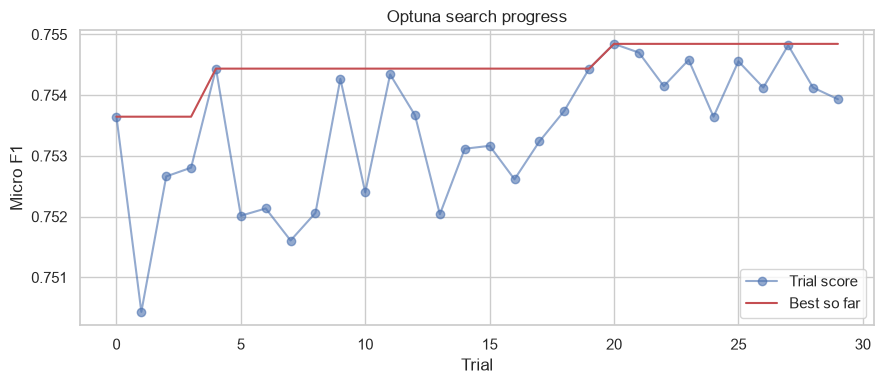

In [33]:
def objective(trial):
    params = {
        'learning_rate':     trial.suggest_float('learning_rate', 0.02, 0.15, log=True),
        'num_leaves':        trial.suggest_int('num_leaves', 31, 255),
        'max_depth':         trial.suggest_int('max_depth', 6, 20),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 100),
        'subsample':         trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.4, 1.0),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
    }
    model = LGBMClassifier(n_estimators=2000, subsample_freq=1, n_jobs=-1, verbose=-1,
                           random_state=RANDOM_STATE, **params)
    model.fit(Xt_fit, y_fit, eval_set=[(Xt_val, y_val)],
              callbacks=[lgb.early_stopping(50, verbose=False)])
    trial.set_user_attr('best_iteration', model.best_iteration_)
    return f1_score(y_val, model.predict(Xt_val), average='micro')


study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

best_params  = study.best_params.copy()
best_n_trees = int(study.best_trial.user_attrs['best_iteration'] * 1.1)

print("Best inner-validation micro-F1:", round(study.best_value, 4))
print("Trees:", best_n_trees)
for k, v in best_params.items():
    print(f"  {k}: {v}")

tdf = study.trials_dataframe()
plt.figure(figsize=(9, 4))
plt.plot(tdf['number'], tdf['value'], 'o-', alpha=0.6, label='Trial score')
plt.plot(tdf['number'], tdf['value'].cummax(), 'r-', label='Best so far')
plt.xlabel('Trial'); plt.ylabel('Micro F1'); plt.legend(); plt.title('Optuna search progress')
plt.tight_layout(); plt.show()

## 7.1 Tuned LightGBM on the untouched validation set

In [34]:
def make_tuned_lgbm():
    return make_pipeline(LGBMClassifier(n_estimators=best_n_trees, subsample_freq=1, n_jobs=-1, verbose=-1,
                                        random_state=RANDOM_STATE, **best_params))

tuned_pipe = make_tuned_lgbm().fit(X_train, y_train)
valid_probas['LightGBM tuned'] = tuned_pipe.predict_proba(X_valid)
all_results.append(score_row('LightGBM tuned', valid_probas['LightGBM tuned'].argmax(axis=1)))

default_lgbm = [r for r in all_results if r['Model'] == 'LightGBM (default settings)'][0]['Micro F1']
print(f"LightGBM default settings: {default_lgbm:.4f}   ->   tuned: {all_results[-1]['Micro F1']:.4f}")

LightGBM default settings: 0.7550   ->   tuned: 0.7573


Tuning moved LightGBM from 0.7550 to 0.7573 on the validation set. That is a small gain, but it is in line with the cross-validation result later on. The best trial used a low learning rate (0.033), a deep tree with 187 leaves and heavy column subsampling (about 41% of columns per tree), which makes sense for a feature set with many overlapping columns.

# 8. CatBoost and ensemble

**CatBoost** handles categorical columns itself with ordered target statistics, which suits the high-cardinality geo columns. It receives the raw categories as text, not one-hot columns. Early stopping uses a 15% slice of the training data.

The **ensemble** averages the predicted probabilities of several models. Different models make different mistakes, so the average is often a little better than any single one. Equal weights are used, which avoids over-fitting the validation set.

In [35]:
class CatBoostModel(BaseEstimator, ClassifierMixin):
    """CatBoost with neighbourhood features and native categorical handling."""

    def __init__(self, iterations=1500, learning_rate=0.1, depth=8, random_state=42, verbose=0):
        self.iterations = iterations
        self.learning_rate = learning_rate
        self.depth = depth
        self.random_state = random_state
        self.verbose = verbose

    def _frame(self, X):
        d = self.geoagg_.transform(X)[self.feature_names_]
        for c in cat_cols + geo_cols:
            d[c] = d[c].astype(str)
        return d

    def fit(self, X, y):
        self.geoagg_ = GeoAggregator().fit(X)
        self.feature_names_ = list(self.geoagg_.transform(X.head(5)).columns)
        F, y = self._frame(X), np.asarray(y)
        F_fit, F_val, y_fit_, y_val_ = train_test_split(F, y, test_size=0.15, stratify=y,
                                                        random_state=self.random_state)
        self.model_ = CatBoostClassifier(iterations=self.iterations, learning_rate=self.learning_rate,
                                         depth=self.depth, loss_function='MultiClass',
                                         random_seed=self.random_state, thread_count=-1,
                                         verbose=self.verbose)
        self.model_.fit(F_fit, y_fit_, cat_features=cat_cols + geo_cols,
                        eval_set=(F_val, y_val_), early_stopping_rounds=100)
        self.classes_ = np.array([0, 1, 2])
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(self._frame(X))

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)


def make_catboost(verbose=0):
    return CatBoostModel(iterations=CB_ITERATIONS, random_state=RANDOM_STATE, verbose=verbose)


t0 = time.time()
cb_valid_model = make_catboost(verbose=250).fit(X_train, y_train)
valid_probas['CatBoost'] = cb_valid_model.predict_proba(X_valid)
all_results.append(score_row('CatBoost', valid_probas['CatBoost'].argmax(axis=1)))
print(f"CatBoost done in {time.time() - t0:.0f}s | micro-F1 = {all_results[-1]['Micro F1']:.4f}")

0:	learn: 1.0268973	test: 1.0255726	best: 1.0255726 (0)	total: 509ms	remaining: 12m 42s
250:	learn: 0.5601520	test: 0.5631198	best: 0.5631198 (250)	total: 2m 7s	remaining: 10m 34s
500:	learn: 0.5344779	test: 0.5581871	best: 0.5581871 (500)	total: 4m 20s	remaining: 8m 38s
750:	learn: 0.5131222	test: 0.5564109	best: 0.5564109 (750)	total: 6m 31s	remaining: 6m 30s
1000:	learn: 0.4937055	test: 0.5551297	best: 0.5551233 (999)	total: 8m 48s	remaining: 4m 23s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.5548159559
bestIteration = 1112

Shrink model to first 1113 iterations.
CatBoost done in 640s | micro-F1 = 0.7527


In [36]:
# Members that can be combined, and how to build each one fresh for the final fit
member_factories = {
    'LightGBM tuned': make_tuned_lgbm,
    'XGBoost':        lambda: make_pipeline(make_xgb()),
    'CatBoost':       make_catboost,
}

configs = {name: [name] for name in member_factories}       # single models
for r in (2, 3):
    for combo in itertools.combinations(member_factories, r):
        ens_name = ' + '.join(combo) + ' (ensemble)'
        configs[ens_name] = list(combo)
        avg = np.mean([valid_probas[m] for m in combo], axis=0)
        all_results.append(score_row(ens_name, avg.argmax(axis=1)))

comparison_df = pd.DataFrame(all_results).sort_values('Micro F1', ascending=False).reset_index(drop=True)
comparison_df.round(4)

,Model,Micro F1,Macro F1,F1 Grade 1,F1 Grade 2,F1 Grade 3
0,LightGBM tuned + CatBoost (ensemble),0.7576,0.7111,0.6220,0.8019,0.7093
1,LightGBM tuned + XGBoost (ensemble),0.7574,0.7118,0.6242,0.8012,0.7101
2,LightGBM tuned,0.7573,0.7115,0.6230,0.8012,0.7103
3,LightGBM tuned + XGBoost + CatBoost (ensemble),0.7572,0.7112,0.6231,0.8014,0.7093
4,XGBoost + CatBoost (ensemble),0.7571,0.7111,0.6235,0.8015,0.7084
5,XGBoost,0.7562,0.7111,0.6245,0.8001,0.7086
6,LightGBM (default settings),0.7550,0.7102,0.6238,0.7988,0.7082
7,Random Forest,0.7534,0.7033,0.6070,0.7993,0.7037
8,CatBoost,0.7527,0.7048,0.6137,0.7984,0.7023
9,Logistic Regression,0.7444,0.6909,0.5861,0.7919,0.6947


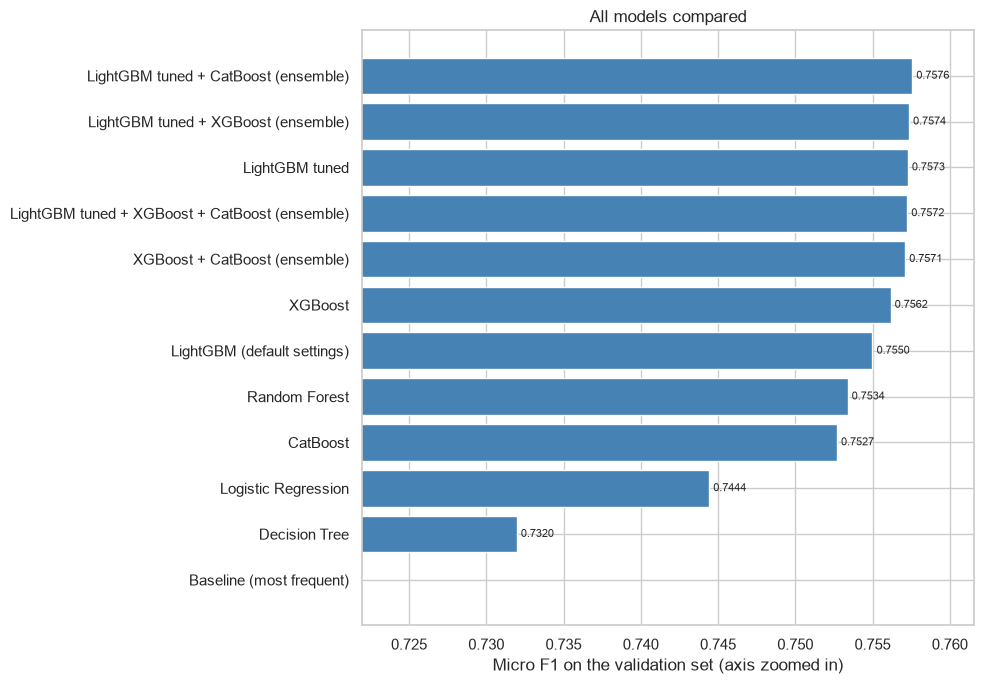

In [37]:
plot_df = comparison_df.sort_values('Micro F1')
fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(plot_df['Model'], plot_df['Micro F1'], color='steelblue')
ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=8)
real = plot_df[~plot_df['Model'].str.startswith('Baseline')]
ax.set_xlim(real['Micro F1'].min() - 0.01, plot_df['Micro F1'].max() + 0.004)
ax.set_xlabel('Micro F1 on the validation set (axis zoomed in)')
ax.set_title('All models compared')
plt.tight_layout(); plt.show()

## 8.1 Choose the final model

Rule: an ensemble is chosen only if it beats the best **single** model by at least `MIN_GAIN` (0.0005 micro-F1). A gain smaller than that is within the noise between validation splits, and a single model is simpler to explain, deploy and maintain.

In [38]:
cfg_scores = {}
for name, members in configs.items():
    cfg_scores[name] = comparison_df.loc[comparison_df['Model'] == name, 'Micro F1'].iloc[0]

singles   = {n: s for n, s in cfg_scores.items() if len(configs[n]) == 1}
ensembles = {n: s for n, s in cfg_scores.items() if len(configs[n]) > 1}

best_single = max(singles, key=singles.get)
final_name = best_single
if ensembles:
    best_ens = max(ensembles, key=ensembles.get)
    if ensembles[best_ens] - singles[best_single] >= MIN_GAIN:
        final_name = best_ens

final_members = configs[final_name]
final_valid_proba = np.mean([valid_probas[m] for m in final_members], axis=0)
final_valid_pred = final_valid_proba.argmax(axis=1)

print(f"Best single model : {best_single} ({singles[best_single]:.4f})")
if ensembles:
    print(f"Best ensemble     : {best_ens} ({ensembles[best_ens]:.4f})")
print(f"\nFinal choice      : {final_name}")
print(f"Validation micro-F1 = {cfg_scores[final_name]:.4f}")

Best single model : LightGBM tuned (0.7573)
Best ensemble     : LightGBM tuned + CatBoost (ensemble) (0.7576)

Final choice      : LightGBM tuned
Validation micro-F1 = 0.7573


The best ensemble (LightGBM + CatBoost) scores 0.7576 against 0.7573 for the tuned LightGBM on its own. A difference of 0.0003 is well inside the noise between validation splits, and it falls short of the 0.0005 threshold I set, so the rule picked the single model. CatBoost on its own (0.7527) came in behind LightGBM and XGBoost and was the slowest model to train, which I did not expect given that it handles the raw categories natively.

# 9. Evaluation and interpretation

## 9.1 Detailed report for the final model

              precision    recall  f1-score   support

     Grade 1      0.688     0.569     0.623      5025
     Grade 2      0.760     0.847     0.801     29652
     Grade 3      0.771     0.659     0.710     17444

    accuracy                          0.757     52121
   macro avg      0.740     0.692     0.711     52121
weighted avg      0.757     0.757     0.754     52121



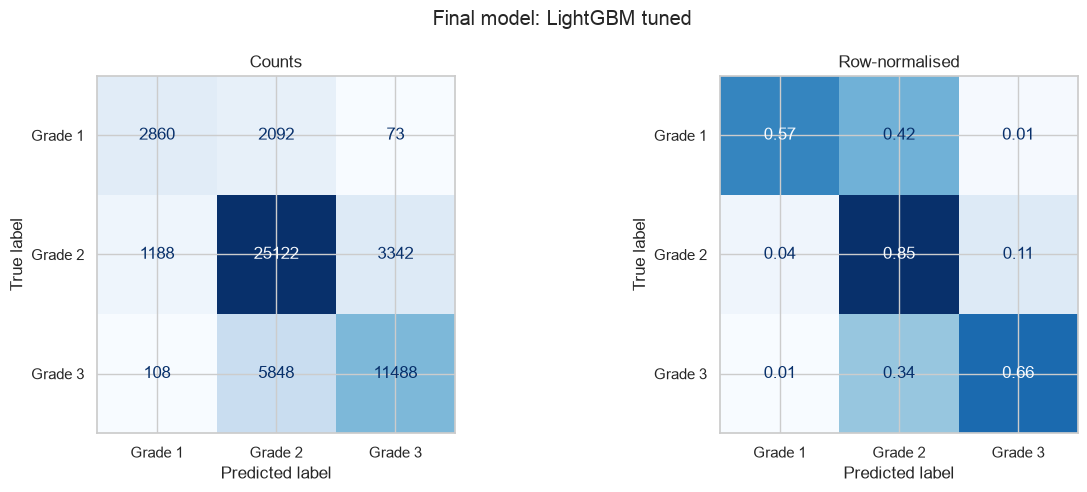

In [39]:
print(classification_report(y_valid, final_valid_pred,
                            target_names=['Grade 1', 'Grade 2', 'Grade 3'], digits=3, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_valid, final_valid_pred, display_labels=['Grade 1', 'Grade 2', 'Grade 3'],
                                        cmap='Blues', ax=axes[0], colorbar=False)
axes[0].set_title('Counts')
ConfusionMatrixDisplay.from_predictions(y_valid, final_valid_pred, display_labels=['Grade 1', 'Grade 2', 'Grade 3'],
                                        normalize='true', values_format='.2f', cmap='Blues', ax=axes[1], colorbar=False)
axes[1].set_title('Row-normalised')
plt.suptitle(f'Final model: {final_name}')
plt.tight_layout(); plt.show()

Grade 2 is the easiest class (F1 0.801, recall 0.847). Grade 1 is the hardest, with recall of only 0.569, and Grade 3 recall is 0.659. The model leans towards the middle grade, which is what you would expect when the middle class is the biggest and sits next to both of the others.

## 9.2 Cross-validation of the tuned LightGBM

One validation split can be lucky or unlucky. 5-fold stratified cross-validation gives a steadier estimate. The pipeline contains both encoders, so there is no leakage between folds. (This takes several minutes. Skipped when `RUN_CV` is False.)

In [40]:
if RUN_CV:
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    oof_proba = cross_val_predict(make_tuned_lgbm(), X, y, cv=cv, method='predict_proba', n_jobs=1)
    oof_pred = oof_proba.argmax(axis=1)
    cv_micro = f1_score(y, oof_pred, average='micro')
    print("Tuned LightGBM, 5-fold cross-validation")
    print("  Micro F1:", round(cv_micro, 4))
    print("  Macro F1:", round(f1_score(y, oof_pred, average='macro'), 4))
else:
    cv_micro = None
    print("RUN_CV is False: skipped.")

Tuned LightGBM, 5-fold cross-validation
  Micro F1: 0.7551
  Macro F1: 0.7096


Cross-validation gives 0.7551 against 0.7573 on the single validation split. The two numbers are close, so the model does not seem to be over-fitted to one lucky split. If I had to quote one number for the project, I would quote the cross-validated one.

## 9.3 Error analysis: where does the final model still fail?

In [41]:
ea = X_valid.copy()
ea['true'] = y_valid.values
ea['pred'] = final_valid_pred
ea['correct'] = ea['true'] == ea['pred']

errors = ea[~ea['correct']]
two_off = (abs(errors['true'] - errors['pred']) == 2).mean()
print(f"Overall accuracy: {ea['correct'].mean():.4f}")
print(f"Mistakes that are one grade off          : {1 - two_off:.1%}")
print(f"Mistakes that are two grades off (1 <-> 3): {two_off:.1%}")


def accuracy_by(col):
    return ea.groupby(col)['correct'].agg(accuracy='mean', buildings='size').round(3)

for col in ['is_mud_based', 'is_rc', 'age_bucket', 'count_floors_pre_eq']:
    print(f"\nAccuracy by {col}")
    display(accuracy_by(col))

Overall accuracy: 0.7573
Mistakes that are one grade off          : 98.6%
Mistakes that are two grades off (1 <-> 3): 1.4%

Accuracy by is_mud_based


,accuracy,buildings
is_mud_based,,
0,0.722,7713
1,0.763,44408



Accuracy by is_rc


,accuracy,buildings
is_rc,,
0,0.758,49100
1,0.744,3021



Accuracy by age_bucket


,accuracy,buildings
age_bucket,,
0,0.741,12025
1,0.761,7759
2,0.763,14029
3,0.768,8442
4,0.756,6699
5,0.755,3167



Accuracy by count_floors_pre_eq


,accuracy,buildings
count_floors_pre_eq,,
1,0.722,8035
2,0.765,31461
3,0.762,10989
4,0.740,1107
5,0.786,472
6,0.787,47
7,1.000,10


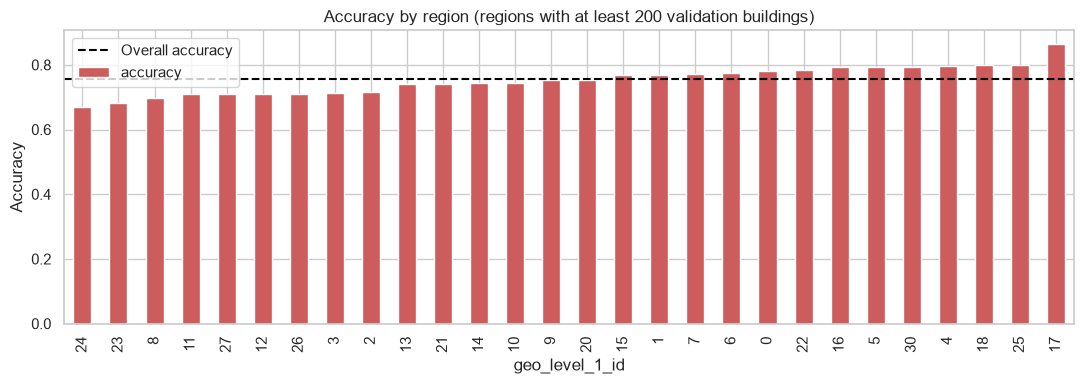

Weakest 5 regions:


,accuracy,buildings
geo_level_1_id,,
24,0.670,261
23,0.682,217
8,0.696,3775
11,0.709,1611
27,0.710,2561


In [42]:
region_acc = accuracy_by('geo_level_1_id')
enough = region_acc[region_acc['buildings'] >= 200]
region_acc = (enough if len(enough) > 0 else region_acc).sort_values('accuracy')

fig, ax = plt.subplots(figsize=(11, 4))
region_acc['accuracy'].plot(kind='bar', color='indianred', ax=ax)
ax.axhline(ea['correct'].mean(), color='black', ls='--', label='Overall accuracy')
ax.set_ylabel('Accuracy'); ax.set_xlabel('geo_level_1_id'); ax.legend()
ax.set_title('Accuracy by region (regions with at least 200 validation buildings)')
plt.tight_layout(); plt.show()
print("Weakest 5 regions:")
display(region_acc.head(5))

**Mistakes are mostly near-misses.** 98.6% of the wrong predictions are off by one grade, and only 1.4% confuse Grade 1 with Grade 3. Accuracy is fairly even across age groups (0.741 to 0.768) and across floor counts that have enough buildings. It is lower for non-mud buildings (0.722 against 0.763) and for single-storey buildings (0.722).

By region, the weakest are 24 (0.670, only 261 validation buildings), 23 (0.682, 217 buildings) and 8 (0.696 on 3,775 buildings). Region 8 is the one worth caring about because of its size, and it is also a region with a very mixed outcome (roughly half Grade 3, half Grade 2), so it is hard for a reason.

## 9.4 Feature importance (tuned LightGBM)

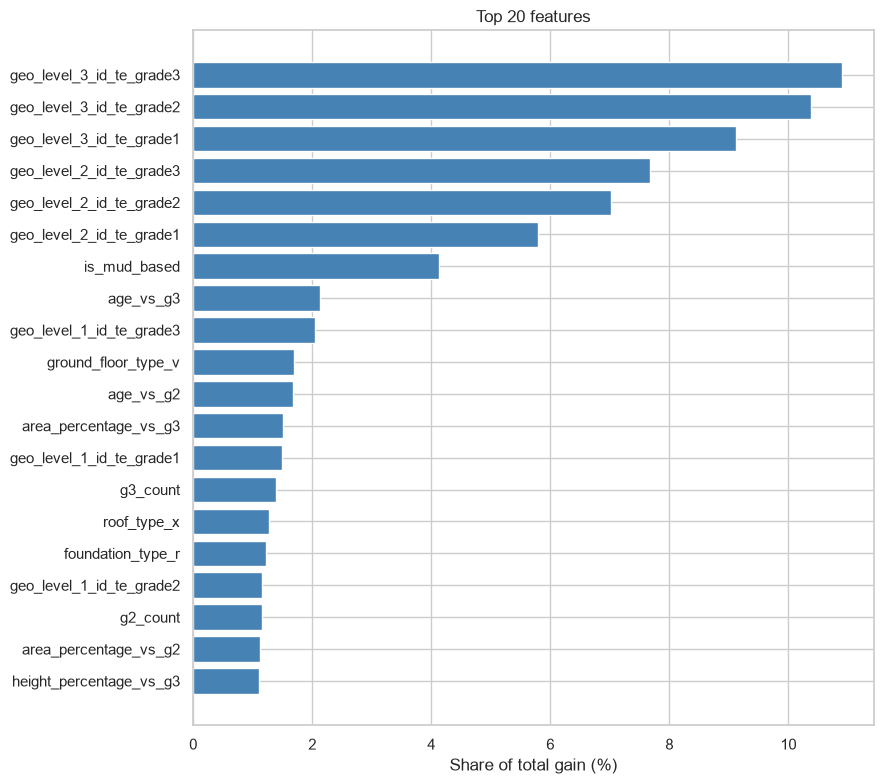

Neighbourhood (GeoAggregator) features account for 24.3% of total gain.


In [43]:
def get_feature_names(prep):
    ohe_names = list(prep.named_transformers_['ohe'].get_feature_names_out(cat_cols + ['geo_level_1_id']))
    te_names = [f"{c}_te_grade{k + 1}" for c in geo_cols for k in range(3)]
    return ohe_names + num_cols + GEO_AGG_COLS + bin_cols + te_names + geo_cols    # same order as build_preprocessor

lgbm_prep  = tuned_pipe.named_steps['prep']
lgbm_model = tuned_pipe.named_steps['model']
feature_names = get_feature_names(lgbm_prep)

importance = pd.Series(lgbm_model.booster_.feature_importance(importance_type='gain'),
                       index=feature_names).sort_values(ascending=False)
top = importance.head(20)[::-1]
plt.figure(figsize=(9, 8))
plt.barh(top.index, top.values / importance.sum() * 100, color='steelblue')
plt.xlabel('Share of total gain (%)'); plt.title('Top 20 features')
plt.tight_layout(); plt.show()

new_share = importance[importance.index.isin(GEO_AGG_COLS)].sum() / importance.sum()
print(f"Neighbourhood (GeoAggregator) features account for {new_share:.1%} of total gain.")

The target-encoded region columns for levels 3 and 2 take the top six places, which matches what the EDA suggested: where a building stands tells you a lot about how it fared. `is_mud_based` comes next. The neighbourhood features (Section 5.5) account for 24.3% of the total gain and several of them reach the top 20, for example `age_vs_g3` (how old a building is compared with the others in its level 3 region) and `g3_count` (how many buildings were surveyed in that region).

## 9.5 SHAP: what pushes a building towards Grade 3?

Importance says which features matter. SHAP shows the **direction**: for example, whether a mud-based structure or a tall building pushes the prediction towards Grade 3 (almost complete destruction).

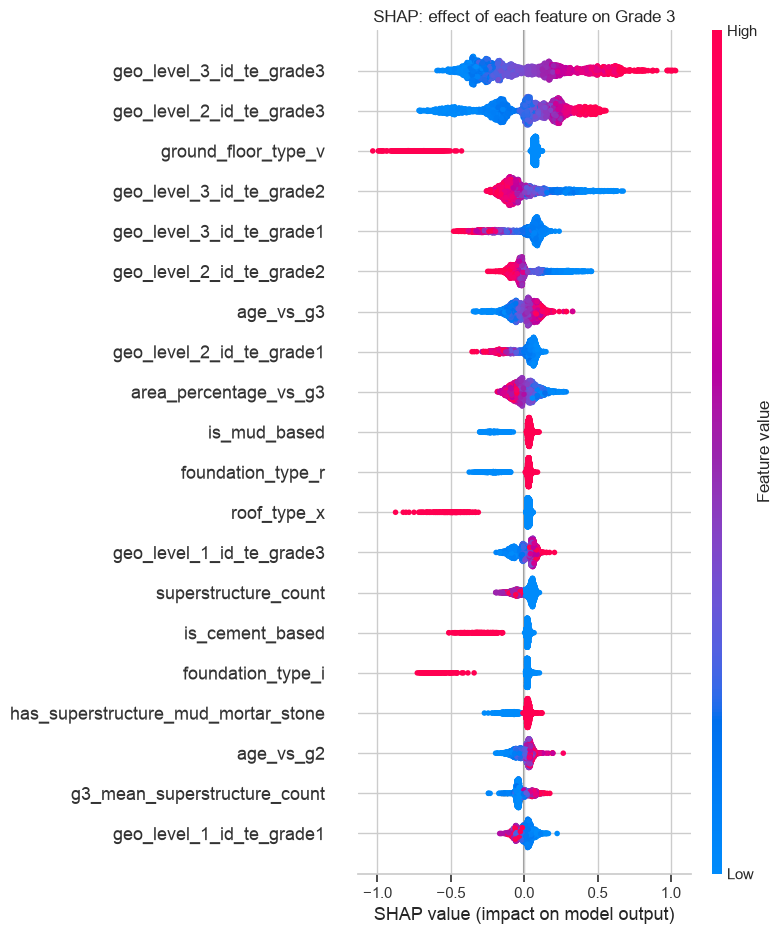

In [44]:
sample_idx = X_valid.sample(min(3000, len(X_valid)), random_state=RANDOM_STATE).index
X_sample = tuned_pipe.named_steps['geoagg'].transform(X_valid.loc[sample_idx])
Xs = pd.DataFrame(lgbm_prep.transform(X_sample), columns=feature_names)

sv = shap.TreeExplainer(lgbm_model).shap_values(Xs)
sv_grade3 = sv[2] if isinstance(sv, list) else sv[:, :, 2]

shap.summary_plot(sv_grade3, Xs, max_display=20, show=False)
plt.title('SHAP: effect of each feature on Grade 3')
plt.tight_layout(); plt.show()

How to read this: each dot is a building, and a dot to the right of zero pushes the prediction towards Grade 3. A high Grade 3 rate for the building's region pushes strongly towards Grade 3, as expected. A few categorical values push firmly the other way: `ground_floor_type_v`, `roof_type_x`, `foundation_type_i` and `is_cement_based` all lower the chance of Grade 3 when they are present. `is_mud_based` and `foundation_type_r` push slightly towards Grade 3. The category letters are anonymised in this dataset, so I cannot say what those types actually are.

# 10. Final training and submission

The chosen model(s) are trained on **all** labelled buildings (no validation hold-out), then used to predict the test set. The test data goes through exactly the same steps: `clean_data()` with the **training** age median, then `add_features()`.

This section needs `test_values.csv` next to the notebook. If the file is missing, the prediction cell prints a message and skips the submission step instead of failing.

In [45]:
t0 = time.time()
final_models = {}
for m in final_members:
    print("Training on all labelled data:", m)
    final_models[m] = member_factories[m]().fit(X, y)
print(f"Done in {time.time() - t0:.0f}s")

joblib.dump({'models': final_models, 'age_median': AGE_MEDIAN, 'final_name': final_name,
             'feature_columns': list(X.columns)}, 'final_models.joblib')
print("Saved: final_models.joblib")

Training on all labelled data: LightGBM tuned
Done in 53s
Saved: final_models.joblib


In [46]:
def predict_final(X_new):
    proba = np.mean([model.predict_proba(X_new) for model in final_models.values()], axis=0)
    return proba.argmax(axis=1) + 1                      # back to damage grades 1, 2, 3


if os.path.exists(TEST_VALUES_PATH):
    test_raw = pd.read_csv(TEST_VALUES_PATH)
    test_clean, _ = clean_data(test_raw, age_median=AGE_MEDIAN)          # training median, not the test median
    X_test = add_features(test_clean.drop(columns=['building_id']))[X.columns]

    submission = pd.DataFrame({'building_id': test_raw['building_id'],
                               'damage_grade': predict_final(X_test)})
    submission.to_csv('submission.csv', index=False)

    print("Test buildings:", len(test_raw), "| unknown ages in test:", int(test_clean['age_unknown'].sum()))
    print("\nPredicted class shares (test):")
    print((submission['damage_grade'].value_counts(normalize=True).sort_index() * 100).round(1).to_string())
    print("Training class shares        :", (df['damage_grade'].value_counts(normalize=True).sort_index() * 100).round(1).tolist())
else:
    submission = None
    print(f"{TEST_VALUES_PATH} not found. Put it next to the notebook and run this cell again.")

test_values.csv not found. Put it next to the notebook and run this cell again.


In [47]:
if submission is not None:
    assert submission['damage_grade'].isin([1, 2, 3]).all(), "invalid grades"
    assert submission['building_id'].is_unique, "duplicate ids"
    assert submission.notna().all().all(), "missing values"
    if os.path.exists(SUBMISSION_FORMAT_PATH):
        fmt = pd.read_csv(SUBMISSION_FORMAT_PATH)
        assert list(fmt.columns) == list(submission.columns), "columns differ from submission_format.csv"
        assert set(fmt['building_id']) == set(submission['building_id']), "ids differ from submission_format.csv"
        print("Format matches submission_format.csv")
    print("Submission checks passed. File saved: submission.csv")
    display(submission.head())

# 11. Project summary

In [48]:
summary = comparison_df[['Model', 'Micro F1', 'Macro F1', 'F1 Grade 1']].round(4).head(8)
display(summary)

default_score = [r for r in all_results if r['Model'] == 'LightGBM (default settings)'][0]['Micro F1']
print(f"Final model                    : {final_name}")
print(f"Validation micro-F1            : {cfg_scores[final_name]:.4f}")
if cv_micro is not None:
    print(f"Tuned LightGBM 5-fold CV       : {cv_micro:.4f}")
print(f"LightGBM default -> tuned      : {default_score:.4f} -> {singles['LightGBM tuned']:.4f}")
print(f"Neighbourhood feature share    : {new_share:.1%} of LightGBM gain")

comparison_df.round(4).to_csv('model_comparison.csv', index=False)
print("\nSaved: model_comparison.csv")

,Model,Micro F1,Macro F1,F1 Grade 1
0,LightGBM tuned + CatBoost (ensemble),0.7576,0.7111,0.6220
1,LightGBM tuned + XGBoost (ensemble),0.7574,0.7118,0.6242
2,LightGBM tuned,0.7573,0.7115,0.6230
3,LightGBM tuned + XGBoost + CatBoost (ensemble),0.7572,0.7112,0.6231
4,XGBoost + CatBoost (ensemble),0.7571,0.7111,0.6235
5,XGBoost,0.7562,0.7111,0.6245
6,LightGBM (default settings),0.7550,0.7102,0.6238
7,Random Forest,0.7534,0.7033,0.6070


Final model                    : LightGBM tuned
Validation micro-F1            : 0.7573
Tuned LightGBM 5-fold CV       : 0.7551
LightGBM default -> tuned      : 0.7550 -> 0.7573
Neighbourhood feature share    : 24.3% of LightGBM gain

Saved: model_comparison.csv


## Conclusions

**What worked**
- Location is the strongest signal by a wide margin. Target encoding the region IDs (done out-of-fold, to avoid leaking the labels) and adding neighbourhood statistics for each region were the changes that helped the most. In an earlier version of this notebook without the neighbourhood features, the tuned LightGBM scored 0.7544 on validation and 0.7514 in cross-validation. With them, and after re-tuning, it scores 0.7573 and 0.7551.
- Putting everything into sklearn pipelines kept cross-validation honest and made applying the model to the test set a one-line job.

**What did not**
- Class weights lowered the headline score, as expected, and did not improve the Grade 1 F1.
- CatBoost and the ensembles did not give a gain worth the extra complexity. The simpler single model won.
- Tuning was worth about 0.002 and not more. The top models are close enough that the remaining gains probably need new information rather than a different algorithm.

**Limits of this work**
- The category values are anonymised letters, so I can say which ones matter but not what they mean in the real world.
- One random validation split plus cross-validation of a single model. I did not repeat the whole comparison under cross-validation.
- The model is trained on one earthquake. The strong dependence on region means it should not be expected to transfer to a different event.
- I treated the damage grade as three unrelated classes. The grades are ordered, and a model that uses that could do better.

**What I would try next**
- An ordinal approach (for example two stacked binary classifiers: "worse than Grade 1" and "worse than Grade 2").
- A Tableau dashboard of damage by region and material, and a small Streamlit app that predicts a grade from building details.
- Upload the submission to DrivenData and record the leaderboard score here.